# Assignment 4 - Knowledge Distillation (Q1) + Hardware-Aware NAS (Q2)
**Edge Computing & Intelligent Systems** - everything runs in this one Kaggle notebook.

### What this notebook does (simple words)
1. Writes all the project files (`.py`) into the folder `/kaggle/working/edge_assignment4` (the cells starting with `%%writefile`).
2. Runs them one by one: teacher -> students (alone) -> students (with teacher) -> ONNX, then NAS -> best model -> ONNX, then benchmark.
3. Saves every model, result table and figure inside that same folder, and makes **one ZIP** at the end that you upload to GitHub.

### Before you press Run (Kaggle right-side panel -> Session options)
* **Accelerator = GPU T4 x2** (pick T4, not P100; only one GPU is used)
* **Internet = On** (needed to download CIFAR and the pretrained weights)
* **Step 1 - smoke test:** keep `FAST_DEV = True` in the first code cell and run all cells (about 10-15 min). It trains on tiny data just to prove nothing crashes. Its outputs go to `_dev_outputs/` and are NOT put in the final zip.
* **Step 2 - real run:** set `FAST_DEV = False`, then use **Save Version -> Save & Run All (Commit)** so it keeps running even if you close the browser.

### How many models are trained and how long (rough guess on a T4 GPU)
| Part | What | Trainings | About |
|---|---|---|---|
| Q1 | ResNet-50 teacher (15 epochs) | 1 | 8-12 min |
| Q1 | Baseline students (20 epochs each, no teacher) | 3 | SqueezeNet 3-4, MobileNetV2 5-7, EfficientNet-Lite0 7-10 min |
| Q1 | KD students (20 epochs each, teacher helps) | 3 | each is ~3-4 min slower than its baseline |
| Q2 | NAS search: short trainings of candidate designs (5 epochs each) | up to 60 | 20-40 min in total |
| Q2 | Best NAS design trained from scratch (40 epochs) | 1 | 4-8 min |
| - | ONNX export (7 + 6 models), ONNX CPU inference, benchmark | - | 5-10 min |

**Total: 7 big trainings in Q1 + about 61 small trainings in Q2, roughly 1.5 to 2.5 hours.** These are estimates; the real numbers depend on the GPU Kaggle gives you (the notebook prints the real time of every run).

In [7]:
# ============ STEP 0 : SETTINGS + FOLDERS  (run this first) ============
FAST_DEV = False     # True = tiny smoke test (10-15 min).  False = the REAL full run.

import os, sys, platform
os.environ["FAST_DEV"] = "1" if FAST_DEV else "0"       # the scripts read this
ROOT = "/kaggle/working/edge_assignment4" if os.path.exists("/kaggle/working") else os.path.abspath("edge_assignment4")
for d in ["q1_distillation", "q2_nas", "onnx_inference", "benchmarking", "checkpoints", "onnx_models", "results", "screenshots"]:
    os.makedirs(os.path.join(ROOT, d), exist_ok=True)
os.chdir(ROOT)
RES = os.path.join(ROOT, "_dev_outputs", "results") if FAST_DEV else os.path.join(ROOT, "results")   # where result files will appear
print("Working folder :", os.getcwd())
print("MODE           :", "SMOKE TEST (FAST_DEV) - not for submission" if FAST_DEV else "REAL RUN")

Working folder : /kaggle/working/edge_assignment4
MODE           : REAL RUN


In [8]:
!pip install -q timm onnx onnxruntime onnxscript

In [9]:
# environment info (good for the report)
import torch, torchvision, subprocess
print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("CPU cores:", os.cpu_count())
print(subprocess.run("lscpu | grep -i 'model name'", shell=True, capture_output=True, text=True).stdout.strip())

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130
CUDA available: True | Tesla T4
CPU cores: 4
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


## Shared files (settings + helper code)

In [10]:
%%writefile requirements.txt
torch
torchvision
timm
onnx
onnxruntime
onnxscript
numpy
pandas
matplotlib
pillow

Overwriting requirements.txt


In [11]:
%%writefile config.py
"""
config.py - ONE place for every setting of the assignment.
Change numbers here (not inside the other scripts).
FAST_DEV=1 (environment variable) = tiny smoke test: 1 epoch, small data, outputs go to _dev_outputs/.
"""
import os

FAST_DEV = os.environ.get("FAST_DEV", "0") == "1"
SEED = 42

# ------------------------------------------------------------------ Q1 : knowledge distillation (CIFAR-100)
Q1_NUM_CLASSES = 100
Q1_IMG_SIZE = 96                 # CIFAR images (32x32) are enlarged to 96x96 before entering the networks
Q1_MEAN = (0.485, 0.456, 0.406)  # ImageNet statistics (we start from ImageNet-pretrained weights)
Q1_STD = (0.229, 0.224, 0.225)
Q1_BATCH = 256
TEACHER_EPOCHS = 15
STUDENT_EPOCHS = 20
STUDENTS = ["mobilenetv2", "squeezenet", "efficientnet_lite0"]
PRETRAINED = True                # same ImageNet start for teacher, baseline students and KD students
WEIGHT_DECAY = 5e-4
LR = {"resnet50": 0.05, "mobilenetv2": 0.05, "squeezenet": 0.01, "efficientnet_lite0": 0.03}

KD_TEMPERATURE = 4.0             # softens teacher/student probabilities
KD_ALPHA = 0.7                   # weight of soft-label loss  (1-alpha = weight of hard-label loss)
KD_FEATURE_BETA = 2.0            # weight of feature-based distillation loss

# ------------------------------------------------------------------ Q2 : hardware-aware NAS (CIFAR-10)
Q2_NUM_CLASSES = 10
Q2_MEAN = (0.4914, 0.4822, 0.4465)
Q2_STD = (0.2470, 0.2435, 0.2616)
Q2_BATCH = 256
NAS_VAL_SIZE = 5000              # part of the CIFAR-10 train set kept aside for validation
NAS_SEARCH_TRAIN = 20000         # images used to train every candidate during the search
NAS_CANDIDATE_EPOCHS = 5
NAS_POPULATION = 12
NAS_CYCLES = 48                  # total trained candidates = population + cycles
NAS_TOURNAMENT = 4
NAS_FINAL_EPOCHS = 40
NAS_LR = 3e-3                    # AdamW + one-cycle schedule for candidates and for the final model
NAS_WD = 0.01

# deployment constraints (measured on CPU, 1 thread, batch size 1)
MAX_LATENCY_MS = 8.0
MAX_MODEL_SIZE_MB = 2.0
MAX_PEAK_MEM_MB = 20.0
SCORE_LATENCY_WEIGHT = 0.05      # score = val_acc - w1*(latency/max) - w2*(size/max)
SCORE_SIZE_WEIGHT = 0.05

# ------------------------------------------------------------------ FAST_DEV overrides (smoke test only)
if FAST_DEV:
    TEACHER_EPOCHS = 1
    STUDENT_EPOCHS = 1
    NAS_VAL_SIZE = 500
    NAS_SEARCH_TRAIN = 1500
    NAS_CANDIDATE_EPOCHS = 1
    NAS_POPULATION = 3
    NAS_CYCLES = 3
    NAS_FINAL_EPOCHS = 1
    DEV_TRAIN_SUBSET = 2000
    DEV_TEST_SUBSET = 1000

Overwriting config.py


In [12]:
%%writefile common.py
"""
common.py - helpers used by every script:
  * folders, seeds, device
  * CIFAR loading + a fast GPU data pipeline (augmentation, resizing, normalising)
  * the generic training loop `fit`
  * checkpoint, ONNX, ONNX-Runtime and timing helpers
"""
import copy
import csv
import io
import json
import math
import os
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import config

# ----------------------------------------------------------------------------- folders
ROOT = os.path.dirname(os.path.abspath(__file__))
OUT = os.path.join(ROOT, "_dev_outputs") if config.FAST_DEV else ROOT
CKPT_DIR = os.path.join(OUT, "checkpoints")
ONNX_DIR = os.path.join(OUT, "onnx_models")
RESULTS_DIR = os.path.join(OUT, "results")
for _d in (CKPT_DIR, ONNX_DIR, RESULTS_DIR):
    os.makedirs(_d, exist_ok=True)


def _pick_data_dir():
    for base in ("/kaggle/temp", "/tmp"):
        try:
            os.makedirs(base + "/data", exist_ok=True)
            return base + "/data"
        except OSError:
            pass
    return os.path.join(ROOT, "data")


DATA_DIR = _pick_data_dir()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=config.SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------- data
def load_cifar(name):
    """Returns uint8 tensors (N,3,32,32) + labels + class names. name = 'cifar10' | 'cifar100'."""
    import torchvision
    cls = {"cifar10": torchvision.datasets.CIFAR10, "cifar100": torchvision.datasets.CIFAR100}[name]
    tr = cls(DATA_DIR, train=True, download=True)
    te = cls(DATA_DIR, train=False, download=True)

    def to_tensor(a):
        return torch.from_numpy(np.ascontiguousarray(a)).permute(0, 3, 1, 2).contiguous()

    xtr, ytr = to_tensor(tr.data), torch.tensor(tr.targets, dtype=torch.long)
    xte, yte = to_tensor(te.data), torch.tensor(te.targets, dtype=torch.long)
    if config.FAST_DEV:
        g = torch.Generator().manual_seed(0)
        i = torch.randperm(len(xtr), generator=g)[:config.DEV_TRAIN_SUBSET]
        j = torch.randperm(len(xte), generator=g)[:config.DEV_TEST_SUBSET]
        xtr, ytr, xte, yte = xtr[i], ytr[i], xte[j], yte[j]
    return xtr, ytr, xte, yte, list(tr.classes)


def split_train_val(x, y, val_size, seed=config.SEED):
    g = torch.Generator().manual_seed(seed)
    p = torch.randperm(len(x), generator=g)
    v, t = p[:val_size], p[val_size:]
    return x[t], y[t], x[v], y[v]


class Preprocess(nn.Module):
    def __init__(self, mean, std, size):
        super().__init__()
        self.size = int(size)
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1))

    def forward(self, x):
        if self.size != x.shape[-1]:
            x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std


class Deployable(nn.Module):
    def __init__(self, model, pre):
        super().__init__()
        self.pre, self.model = pre, model

    def forward(self, x):
        return self.model(self.pre(x))


def augment_batch(x, pad=4):
    b, c, h, w = x.shape
    dev = x.device
    flip = torch.rand(b, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    i = torch.randint(0, 2 * pad + 1, (b,), device=dev)
    j = torch.randint(0, 2 * pad + 1, (b,), device=dev)
    rows = (i[:, None] + torch.arange(h, device=dev))[:, None, :, None]
    cols = (j[:, None] + torch.arange(w, device=dev))[:, None, None, :]
    bidx = torch.arange(b, device=dev)[:, None, None, None]
    cidx = torch.arange(c, device=dev)[None, :, None, None]
    return xp[bidx, cidx, rows, cols]


class GPUData:
    def __init__(self, x, y, pre, batch_size, train):
        self.x, self.y = x.to(DEVICE), y.to(DEVICE)
        self.pre = pre.to(DEVICE)
        self.bs, self.train = batch_size, train

    def __len__(self):
        n = len(self.x)
        return max(1, n // self.bs) if self.train else math.ceil(n / self.bs)

    def __iter__(self):
        n = len(self.x)
        idx = torch.randperm(n, device=DEVICE) if self.train else torch.arange(n, device=DEVICE)
        for k in range(len(self)):
            b = idx[k * self.bs:(k + 1) * self.bs]
            xb = self.x[b].float().div_(255.0)
            if self.train:
                xb = augment_batch(xb)
            xb = self.pre(xb).contiguous(memory_format=torch.channels_last)
            yield xb, self.y[b]


# ----------------------------------------------------------------------------- training loop
def _make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)


@torch.no_grad()
def evaluate(model, data, use_amp=None):
    use_amp = (DEVICE.type == "cuda") if use_amp is None else use_amp
    model.eval()
    correct = total = 0
    for xb, yb in data:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            out = model(xb)
        correct += (out.argmax(1) == yb).sum().item()
        total += len(yb)
    return correct / max(1, total)


def fit(name, model, step_fn, train_data, test_data, epochs, lr, wd,
        extra_modules=(), log_path=None, optimizer="sgd", verbose=True):
    use_amp = DEVICE.type == "cuda"
    params = list(model.parameters()) + [p for m in extra_modules for p in m.parameters()]
    if optimizer == "sgd":
        opt = torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    else:
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    # ---- FIX: guard against zero-length warmup phase (hits newer PyTorch with small FAST_DEV data) ----
    _total = max(epochs * len(train_data), 1)
    _pct   = min(max(0.2, 2.0 / _total), 0.9)   # warmup gets >=2 steps -> no ZeroDivisionError
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=_total, pct_start=_pct)
    # ----------------------------------------------------------------------------------------------------
    scaler = _make_scaler(use_amp)
    logs, t_start = [], time.time()
    for ep in range(1, epochs + 1):
        model.train()
        for m in extra_modules:
            m.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE)
        seen = 0
        for xb, yb in train_data:
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss, logits = step_fn(model, xb, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            loss_sum += loss.detach() * len(yb)
            correct += (logits.detach().argmax(1) == yb).sum()
            seen += len(yb)
        test_acc = evaluate(model, test_data, use_amp)
        row = {"epoch": ep, "train_loss": round(loss_sum.item() / seen, 4),
               "train_acc": round(correct.item() / seen, 4), "test_acc": round(test_acc, 4),
               "epoch_time_s": round(time.time() - t0, 1)}
        logs.append(row)
        if verbose:
            print(f"[{name}] epoch {ep:>2}/{epochs}  loss {row['train_loss']:.3f}  "
                  f"train_acc {row['train_acc']:.3f}  eval_acc {row['test_acc']:.3f}  ({row['epoch_time_s']}s)", flush=True)
    if log_path:
        save_csv(logs, log_path)
    return logs, time.time() - t_start


# ----------------------------------------------------------------------------- files
def save_csv(rows, path):
    if not rows:
        return
    keys = list(rows[0].keys())
    for r in rows:
        for k in r:
            if k not in keys:
                keys.append(k)
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def save_ckpt(model, path, half=False):
    sd = {k: (v.half() if (half and v.is_floating_point()) else v).cpu() for k, v in model.state_dict().items()}
    torch.save(sd, path)


def load_ckpt(model, path):
    sd = torch.load(path, map_location="cpu")
    sd = {k: (v.float() if v.is_floating_point() else v) for k, v in sd.items()}
    model.load_state_dict(sd)
    return model


def count_params_m(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


def file_mb(path):
    return os.path.getsize(path) / 1e6


def state_dict_mb(model):
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    return buf.getbuffer().nbytes / 1e6


# ----------------------------------------------------------------------------- ONNX / ONNX Runtime
def export_onnx(model, pre, path, opset=17):
    wrapper = Deployable(copy.deepcopy(model), copy.deepcopy(pre)).cpu().eval()
    wrapper.to(memory_format=torch.contiguous_format)
    try:
        import timm
        timm.layers.set_exportable(True)
    except Exception:
        pass
    dummy = torch.rand(1, 3, 32, 32)
    common = dict(input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=opset)
    last_err = None
    for extra in ({"dynamo": False}, {}, {"dynamo": True}):
        try:
            torch.onnx.export(wrapper, dummy, path, **common, **extra)
            return wrapper
        except Exception as e:
            last_err = e
    raise RuntimeError(f"ONNX export failed: {last_err}")


def ort_session(path, threads=1):
    import onnxruntime as ort
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.inter_op_num_threads = 1
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])


def ort_logits(sess, x_uint8, bs=200):
    outs = []
    name = sess.get_inputs()[0].name
    for i in range(0, len(x_uint8), bs):
        xb = (x_uint8[i:i + bs].numpy().astype(np.float32)) / 255.0
        outs.append(sess.run(None, {name: xb})[0])
    return np.concatenate(outs)


def timeit_ms(fn, warmup=20, runs=100):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(runs):
        t0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean_ms": float(t.mean()), "p50_ms": float(np.percentile(t, 50)),
            "p95_ms": float(np.percentile(t, 95)), "std_ms": float(t.std())}

Overwriting common.py


## PART 1 (Q1) - Knowledge distillation on CIFAR-100
Idea: a big, smart **teacher** (ResNet-50) is trained first. Then three small **students** learn from it: they copy the teacher's soft answers (with a temperature), the true labels, and the teacher's inner features. We also train the same students **alone** to see how much the teacher really helps.

The next cells only **write the code files**.

In [13]:
%%writefile q1_distillation/teacher.py
"""teacher.py - the big TEACHER network: ResNet-50 (ImageNet-pretrained backbone, new 100-class head)."""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch.nn as nn
import torchvision


class TeacherNet(nn.Module):
    def __init__(self, num_classes=100, pretrained=True):
        super().__init__()
        try:
            m = torchvision.models.resnet50(weights="IMAGENET1K_V1" if pretrained else None)
        except Exception as e:
            print(f"[WARNING] could not download pretrained ResNet-50 ({e}) -> using RANDOM weights")
            m = torchvision.models.resnet50(weights=None)
        self.stem = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = m.layer1, m.layer2, m.layer3, m.layer4
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(2048, num_classes)
        self.feat_channels = 2048

    def forward(self, x, return_feat=False):
        f = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))   # last feature map (intermediate representation)
        logits = self.fc(self.pool(f).flatten(1))
        return (logits, f) if return_feat else logits

Writing q1_distillation/teacher.py


In [14]:
%%writefile q1_distillation/students.py
"""students.py - the three small STUDENT networks: MobileNetV2, SqueezeNet, EfficientNet-Lite0.
Every student has the same interface:
    logits           = student(x)
    logits, features = student(x, return_feat=True)     # features = last feature map (used for feature-based KD)
"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch.nn as nn
import torchvision

STUDENT_NAMES = ["mobilenetv2", "squeezenet", "efficientnet_lite0"]


def _tv(builder, pretrained, label):
    try:
        return builder(weights="IMAGENET1K_V1" if pretrained else None)
    except Exception as e:
        print(f"[WARNING] could not download pretrained {label} ({e}) -> using RANDOM weights")
        return builder(weights=None)


class StudentNet(nn.Module):
    def __init__(self, name, num_classes=100, pretrained=True):
        super().__init__()
        self.name = name
        self.kind = "tv"
        if name == "mobilenetv2":
            m = _tv(torchvision.models.mobilenet_v2, pretrained, name)
            self.body = m.features                                         # -> 1280 channels
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Dropout(0.2), nn.Linear(1280, num_classes))
            self.feat_channels = 1280
        elif name == "squeezenet":
            m = _tv(torchvision.models.squeezenet1_1, pretrained, name)
            self.body = m.features                                         # -> 512 channels
            final = nn.Conv2d(512, num_classes, kernel_size=1)
            nn.init.normal_(final.weight, std=0.01)
            nn.init.zeros_(final.bias)
            self.head = nn.Sequential(nn.Dropout(0.2), final, nn.AdaptiveAvgPool2d(1), nn.Flatten())
            self.feat_channels = 512
        elif name == "efficientnet_lite0":
            import timm
            self.kind = "timm"
            try:
                self.net = timm.create_model("efficientnet_lite0", pretrained=pretrained, num_classes=num_classes)
            except Exception as e:
                print(f"[WARNING] could not download pretrained efficientnet_lite0 ({e}) -> using RANDOM weights")
                self.net = timm.create_model("efficientnet_lite0", pretrained=False, num_classes=num_classes)
            self.feat_channels = self.net.num_features                     # 1280
        else:
            raise ValueError(f"unknown student {name}")

    def forward(self, x, return_feat=False):
        if self.kind == "timm":
            f = self.net.forward_features(x)
            logits = self.net.forward_head(f)
        else:
            f = self.body(x)
            logits = self.head(f)
        return (logits, f) if return_feat else logits

Writing q1_distillation/students.py


In [15]:
%%writefile q1_distillation/distillation.py
"""distillation.py - the knowledge-distillation loss.

total = alpha * T^2 * KL( softmax(student/T) , softmax(teacher/T) )     <- soft targets with temperature
      + (1 - alpha) * CrossEntropy(student, true label)                  <- hard labels
      + beta * FeatureLoss(student features, teacher features)           <- feature-based distillation
"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch.nn as nn
import torch.nn.functional as F


class DistillationLoss(nn.Module):
    def __init__(self, student_channels, teacher_channels, T=4.0, alpha=0.7, beta=2.0, use_feature=True):
        super().__init__()
        self.T, self.alpha, self.beta, self.use_feature = T, alpha, beta, use_feature
        # connector: a 1x1 conv that converts student feature channels into teacher feature channels
        self.connector = (nn.Sequential(nn.Conv2d(student_channels, teacher_channels, 1, bias=False),
                                        nn.BatchNorm2d(teacher_channels)) if use_feature else None)

    def forward(self, s_logits, t_logits, labels, s_feat=None, t_feat=None):
        s_logits, t_logits = s_logits.float(), t_logits.float()
        hard = F.cross_entropy(s_logits, labels)
        soft = F.kl_div(F.log_softmax(s_logits / self.T, dim=1),
                        F.softmax(t_logits / self.T, dim=1), reduction="batchmean") * (self.T ** 2)
        loss = self.alpha * soft + (1.0 - self.alpha) * hard
        feat = s_logits.new_zeros(())
        if self.use_feature and s_feat is not None:
            s = self.connector(s_feat)
            s = F.adaptive_avg_pool2d(s, t_feat.shape[-2:])        # make the spatial sizes equal
            s = F.normalize(s.float(), dim=1)
            t = F.normalize(t_feat.float(), dim=1)
            feat = ((s - t) ** 2).sum(dim=1).mean()
            loss = loss + self.beta * feat
        return loss, {"hard": hard.detach(), "soft": soft.detach(), "feat": feat.detach()}

Writing q1_distillation/distillation.py


In [16]:
%%writefile q1_distillation/train_teacher.py
"""train_teacher.py - trains the ResNet-50 teacher on CIFAR-100.   Run:  python q1_distillation/train_teacher.py [--force]"""
import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch
import torch.nn.functional as F

import config
import common as C
from teacher import TeacherNet


def main(force=False):
    ckpt = os.path.join(C.CKPT_DIR, "q1_teacher_resnet50.pth")
    if os.path.exists(ckpt) and not force:
        print(f"Teacher checkpoint already exists ({ckpt}) - skipping. Use --force to retrain.")
        return
    C.set_seed()
    xtr, ytr, xte, yte, classes = C.load_cifar("cifar100")
    pre = C.Preprocess(config.Q1_MEAN, config.Q1_STD, config.Q1_IMG_SIZE)
    train = C.GPUData(xtr, ytr, pre, config.Q1_BATCH, train=True)
    test = C.GPUData(xte, yte, pre, config.Q1_BATCH, train=False)

    model = TeacherNet(config.Q1_NUM_CLASSES, config.PRETRAINED).to(C.DEVICE).to(memory_format=torch.channels_last)
    print(f"Teacher ResNet-50: {C.count_params_m(model):.1f} M parameters | device: {C.DEVICE}")

    def step(m, x, y):
        logits = m(x).float()
        return F.cross_entropy(logits, y), logits

    logs, secs = C.fit("teacher", model, step, train, test, config.TEACHER_EPOCHS,
                       config.LR["resnet50"], config.WEIGHT_DECAY,
                       log_path=os.path.join(C.RESULTS_DIR, "q1_teacher_training_log.csv"))
    C.save_ckpt(model, ckpt, half=True)      # fp16 weights -> ~47 MB, safe for GitHub's 100 MB limit
    metrics = {"model": "resnet50_teacher", "dataset": "cifar100", "epochs": config.TEACHER_EPOCHS,
               "final_test_acc": logs[-1]["test_acc"], "params_M": round(C.count_params_m(model), 2),
               "train_time_min": round(secs / 60, 2), "checkpoint": os.path.relpath(ckpt, C.ROOT)}
    C.save_json(metrics, os.path.join(C.RESULTS_DIR, "q1_teacher_metrics.json"))
    print("TEACHER DONE:", metrics)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--force", action="store_true")
    main(ap.parse_args().force)

Writing q1_distillation/train_teacher.py


In [17]:
%%writefile q1_distillation/train_baseline.py
"""train_baseline.py - trains the 3 students ALONE (no teacher, plain cross-entropy). This is the comparison group.
Run:  python q1_distillation/train_baseline.py [--student mobilenetv2] [--force]"""
import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch
import torch.nn.functional as F

import config
import common as C
from students import StudentNet


def train_one(name, data, force):
    ckpt = os.path.join(C.CKPT_DIR, f"q1_baseline_{name}.pth")
    if os.path.exists(ckpt) and not force:
        print(f"[{name}] baseline checkpoint exists - skipping.")
        return
    C.set_seed()
    train, test = data
    model = StudentNet(name, config.Q1_NUM_CLASSES, config.PRETRAINED).to(C.DEVICE).to(memory_format=torch.channels_last)
    print(f"\n=== BASELINE {name} (no distillation) | {C.count_params_m(model):.2f} M params ===")

    def step(m, x, y):
        logits = m(x).float()
        return F.cross_entropy(logits, y), logits

    logs, secs = C.fit(f"baseline-{name}", model, step, train, test, config.STUDENT_EPOCHS,
                       config.LR[name], config.WEIGHT_DECAY,
                       log_path=os.path.join(C.RESULTS_DIR, f"q1_baseline_{name}_log.csv"))
    C.save_ckpt(model, ckpt)
    C.save_json({"model": name, "variant": "baseline", "dataset": "cifar100", "epochs": config.STUDENT_EPOCHS,
                 "final_test_acc": logs[-1]["test_acc"], "params_M": round(C.count_params_m(model), 2),
                 "train_time_min": round(secs / 60, 2), "checkpoint": os.path.relpath(ckpt, C.ROOT)},
                os.path.join(C.RESULTS_DIR, f"q1_baseline_{name}_metrics.json"))


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--student", default="all")
    ap.add_argument("--force", action="store_true")
    a = ap.parse_args()
    xtr, ytr, xte, yte, _ = C.load_cifar("cifar100")
    pre = C.Preprocess(config.Q1_MEAN, config.Q1_STD, config.Q1_IMG_SIZE)
    data = (C.GPUData(xtr, ytr, pre, config.Q1_BATCH, True), C.GPUData(xte, yte, pre, config.Q1_BATCH, False))
    for n in (config.STUDENTS if a.student == "all" else [a.student]):
        train_one(n, data, a.force)

Writing q1_distillation/train_baseline.py


In [18]:
%%writefile q1_distillation/train_kd.py
"""train_kd.py - trains the 3 students WITH the teacher (knowledge distillation).
Run:  python q1_distillation/train_kd.py [--student mobilenetv2] [--force]"""
import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch

import config
import common as C
from teacher import TeacherNet
from students import StudentNet
from distillation import DistillationLoss


def train_one(name, teacher, data, force):
    ckpt = os.path.join(C.CKPT_DIR, f"q1_kd_{name}.pth")
    if os.path.exists(ckpt) and not force:
        print(f"[{name}] KD checkpoint exists - skipping.")
        return
    C.set_seed()
    train, test = data
    model = StudentNet(name, config.Q1_NUM_CLASSES, config.PRETRAINED).to(C.DEVICE).to(memory_format=torch.channels_last)
    criterion = DistillationLoss(model.feat_channels, teacher.feat_channels, config.KD_TEMPERATURE,
                                 config.KD_ALPHA, config.KD_FEATURE_BETA, use_feature=True).to(C.DEVICE)
    print(f"\n=== KNOWLEDGE DISTILLATION -> {name} | T={config.KD_TEMPERATURE} alpha={config.KD_ALPHA} "
          f"beta(feature)={config.KD_FEATURE_BETA} ===")

    def step(m, x, y):
        with torch.no_grad():                                   # the teacher only gives advice, it is not trained
            t_logits, t_feat = teacher(x, return_feat=True)
        s_logits, s_feat = m(x, return_feat=True)
        loss, _ = criterion(s_logits, t_logits, y, s_feat, t_feat)
        return loss, s_logits.float()

    logs, secs = C.fit(f"kd-{name}", model, step, train, test, config.STUDENT_EPOCHS,
                       config.LR[name], config.WEIGHT_DECAY, extra_modules=[criterion],
                       log_path=os.path.join(C.RESULTS_DIR, f"q1_kd_{name}_log.csv"))
    C.save_ckpt(model, ckpt)
    C.save_json({"model": name, "variant": "kd", "dataset": "cifar100", "epochs": config.STUDENT_EPOCHS,
                 "temperature": config.KD_TEMPERATURE, "alpha": config.KD_ALPHA, "feature_beta": config.KD_FEATURE_BETA,
                 "final_test_acc": logs[-1]["test_acc"], "params_M": round(C.count_params_m(model), 2),
                 "train_time_min": round(secs / 60, 2), "checkpoint": os.path.relpath(ckpt, C.ROOT)},
                os.path.join(C.RESULTS_DIR, f"q1_kd_{name}_metrics.json"))


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--student", default="all")
    ap.add_argument("--force", action="store_true")
    a = ap.parse_args()

    teacher_ckpt = os.path.join(C.CKPT_DIR, "q1_teacher_resnet50.pth")
    assert os.path.exists(teacher_ckpt), "Train the teacher first (train_teacher.py)."
    teacher = TeacherNet(config.Q1_NUM_CLASSES, pretrained=False)
    C.load_ckpt(teacher, teacher_ckpt)
    teacher = teacher.to(C.DEVICE).to(memory_format=torch.channels_last).eval()
    for p in teacher.parameters():
        p.requires_grad_(False)

    xtr, ytr, xte, yte, _ = C.load_cifar("cifar100")
    pre = C.Preprocess(config.Q1_MEAN, config.Q1_STD, config.Q1_IMG_SIZE)
    data = (C.GPUData(xtr, ytr, pre, config.Q1_BATCH, True), C.GPUData(xte, yte, pre, config.Q1_BATCH, False))
    print(f"Teacher test accuracy: {C.evaluate(teacher, data[1]):.4f}")
    for n in (config.STUDENTS if a.student == "all" else [a.student]):
        train_one(n, teacher, data, a.force)

Writing q1_distillation/train_kd.py


In [19]:
%%writefile q1_distillation/compare_results.py
"""compare_results.py - builds the table: student accuracy WITHOUT vs WITH distillation."""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import config
import common as C

rows = []
t = os.path.join(C.RESULTS_DIR, "q1_teacher_metrics.json")
if os.path.exists(t):
    m = C.load_json(t)
    rows.append({"model": "resnet50 (teacher)", "params_M": m["params_M"], "baseline_acc": "", "kd_acc": "",
                 "final_acc": m["final_test_acc"], "kd_gain": ""})
for n in config.STUDENTS:
    b = os.path.join(C.RESULTS_DIR, f"q1_baseline_{n}_metrics.json")
    k = os.path.join(C.RESULTS_DIR, f"q1_kd_{n}_metrics.json")
    if os.path.exists(b) and os.path.exists(k):
        mb, mk = C.load_json(b), C.load_json(k)
        rows.append({"model": n, "params_M": mb["params_M"], "baseline_acc": mb["final_test_acc"],
                     "kd_acc": mk["final_test_acc"], "final_acc": "",
                     "kd_gain": round(mk["final_test_acc"] - mb["final_test_acc"], 4),
                     "baseline_train_min": mb["train_time_min"], "kd_train_min": mk["train_time_min"]})
C.save_csv(rows, os.path.join(C.RESULTS_DIR, "q1_baseline_vs_kd.csv"))
for r in rows:
    print(r)

Writing q1_distillation/compare_results.py


In [20]:
%%writefile q1_distillation/inference.py
"""inference.py - ONE unified inference pipeline for all trained students (KD or baseline).

Examples
  python q1_distillation/inference.py --all                                   # test accuracy of all 6 students
  python q1_distillation/inference.py --model mobilenetv2 --variant kd        # one student on the CIFAR-100 test set
  python q1_distillation/inference.py --model squeezenet --variant kd --image cat.jpg   # predict one picture
"""
import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import numpy as np
import torch

import config
import common as C
from students import StudentNet


def load_student(name, variant):
    """Builds the student, loads its checkpoint and wraps it with the preprocessing (raw 32x32 in -> logits out)."""
    ckpt = os.path.join(C.CKPT_DIR, f"q1_{variant}_{name}.pth")
    model = StudentNet(name, config.Q1_NUM_CLASSES, pretrained=False)
    C.load_ckpt(model, ckpt)
    pre = C.Preprocess(config.Q1_MEAN, config.Q1_STD, config.Q1_IMG_SIZE)
    return C.Deployable(model, pre).to(C.DEVICE).eval()


@torch.no_grad()
def predict(net, x_uint8, bs=250):
    """x_uint8: (N,3,32,32) uint8 tensor -> predicted class ids (N,) and probabilities (N,100)."""
    probs = []
    for i in range(0, len(x_uint8), bs):
        xb = x_uint8[i:i + bs].to(C.DEVICE).float() / 255.0
        probs.append(torch.softmax(net(xb).float(), dim=1).cpu())
    probs = torch.cat(probs)
    return probs.argmax(1), probs


def load_image(path):
    from PIL import Image
    img = Image.open(path).convert("RGB").resize((32, 32), Image.BILINEAR)
    return torch.from_numpy(np.array(img)).permute(2, 0, 1).unsqueeze(0).contiguous()


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", choices=config.STUDENTS)
    ap.add_argument("--variant", choices=["kd", "baseline"], default="kd")
    ap.add_argument("--image")
    ap.add_argument("--all", action="store_true")
    a = ap.parse_args()

    _, _, xte, yte, classes = C.load_cifar("cifar100")
    todo = [(n, v) for n in config.STUDENTS for v in ("baseline", "kd")] if a.all else [(a.model, a.variant)]
    rows = []
    for n, v in todo:
        if not os.path.exists(os.path.join(C.CKPT_DIR, f"q1_{v}_{n}.pth")):
            print(f"missing checkpoint for {n}/{v}, skipped")
            continue
        net = load_student(n, v)
        if a.image:
            pred, probs = predict(net, load_image(a.image))
            top5 = probs[0].topk(5)
            print(f"{n} ({v}) top-5:", [(classes[i], round(p.item(), 3)) for p, i in zip(top5.values, top5.indices)])
        else:
            pred, _ = predict(net, xte)
            acc = (pred == yte).float().mean().item()
            print(f"{n:<20} {v:<9} CIFAR-100 test accuracy: {acc:.4f}")
            rows.append({"model": n, "variant": v, "test_acc": round(acc, 4)})
    if rows:
        C.save_csv(rows, os.path.join(C.RESULTS_DIR, "q1_inference_summary.csv"))

Writing q1_distillation/inference.py


In [21]:
%%writefile q1_distillation/export_onnx.py
"""export_onnx.py - exports the trained students (KD + baseline) to ONNX and checks them against PyTorch.
The ONNX models take a raw image batch (batch,3,32,32) with pixel values in 0..1 and return the 100 class scores.
Run:  python q1_distillation/export_onnx.py"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import numpy as np
import torch

import config
import common as C
from students import StudentNet

if __name__ == "__main__":
    _, _, xte, _, _ = C.load_cifar("cifar100")
    sample = xte[:64]
    rows = []
    for n in config.STUDENTS:
        for v in ("kd", "baseline"):
            ckpt = os.path.join(C.CKPT_DIR, f"q1_{v}_{n}.pth")
            if not os.path.exists(ckpt):
                print(f"missing {ckpt}, skipped")
                continue
            model = StudentNet(n, config.Q1_NUM_CLASSES, pretrained=False)
            C.load_ckpt(model, ckpt).eval()
            pre = C.Preprocess(config.Q1_MEAN, config.Q1_STD, config.Q1_IMG_SIZE)
            path = os.path.join(C.ONNX_DIR, f"q1_{n}_{v}.onnx")
            wrapper = C.export_onnx(model, pre, path)
            # compare PyTorch (CPU) and ONNX Runtime (CPU) on 64 test images
            x = sample.float() / 255.0
            with torch.no_grad():
                ref = wrapper(x).numpy()
            out = C.ort_logits(C.ort_session(path), sample)
            diff = float(np.abs(ref - out).max())
            agree = float((ref.argmax(1) == out.argmax(1)).mean())
            rows.append({"model": n, "variant": v, "onnx_file": os.path.relpath(path, C.ROOT),
                         "size_mb": round(C.file_mb(path), 2), "max_abs_diff_vs_pytorch": f"{diff:.2e}",
                         "prediction_agreement": agree})
            print(rows[-1])
    C.save_csv(rows, os.path.join(C.RESULTS_DIR, "q1_onnx_export_check.csv"))

Writing q1_distillation/export_onnx.py


### Run Part 1 (each cell can be re-run; finished models are skipped)

In [22]:
# 1) Train the ResNet-50 teacher (about 8-12 min)
!python -u q1_distillation/train_teacher.py

100%|█████████████████████████████████████████| 169M/169M [26:06<00:00, 108kB/s]
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|███████████████████████████████████████| 97.8M/97.8M [00:00<00:00, 225MB/s]
Teacher ResNet-50: 23.7 M parameters | device: cuda
[teacher] epoch  1/15  loss 1.966  train_acc 0.528  eval_acc 0.677  (40.7s)
[teacher] epoch  2/15  loss 1.082  train_acc 0.685  eval_acc 0.634  (29.9s)
[teacher] epoch  3/15  loss 1.011  train_acc 0.705  eval_acc 0.652  (30.6s)
[teacher] epoch  4/15  loss 0.866  train_acc 0.745  eval_acc 0.671  (31.5s)
[teacher] epoch  5/15  loss 0.757  train_acc 0.769  eval_acc 0.677  (32.1s)
[teacher] epoch  6/15  loss 0.655  train_acc 0.799  eval_acc 0.698  (31.7s)
[teacher] epoch  7/15  loss 0.572  train_acc 0.824  eval_acc 0.722  (31.8s)
[teacher] epoch  8/15  loss 0.493  train_acc 0.845  eval_acc 0.730  (31.9s)
[teacher] epoch  9/15  loss 0.422  train_acc 

In [23]:
# 2) Train the 3 students ALONE = baseline, no teacher (about 15-20 min)
!python -u q1_distillation/train_baseline.py

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100%|███████████████████████████████████████| 13.6M/13.6M [00:00<00:00, 124MB/s]

=== BASELINE mobilenetv2 (no distillation) | 2.35 M params ===
[baseline-mobilenetv2] epoch  1/20  loss 2.231  train_acc 0.445  eval_acc 0.633  (18.4s)
[baseline-mobilenetv2] epoch  2/20  loss 1.222  train_acc 0.642  eval_acc 0.604  (15.3s)
[baseline-mobilenetv2] epoch  3/20  loss 1.192  train_acc 0.651  eval_acc 0.628  (15.4s)
[baseline-mobilenetv2] epoch  4/20  loss 1.126  train_acc 0.670  eval_acc 0.627  (15.2s)
[baseline-mobilenetv2] epoch  5/20  loss 1.025  train_acc 0.697  eval_acc 0.630  (15.1s)
[baseline-mobilenetv2] epoch  6/20  loss 0.944  train_acc 0.715  eval_acc 0.636  (15.1s)
[baseline-mobilenetv2] epoch  7/20  loss 0.879  train_acc 0.734  eval_acc 0.653  (15.1s)
[baseline-mobilenetv2] epoch  8/20  loss 0.817  train_acc 0.752  eval_acc 0.594  (15.2s)
[b

In [24]:
# 3) Train the 3 students WITH the teacher = knowledge distillation (about 25-30 min)
!python -u q1_distillation/train_kd.py

Teacher test accuracy: 0.8246

=== KNOWLEDGE DISTILLATION -> mobilenetv2 | T=4.0 alpha=0.7 beta(feature)=2.0 ===
[kd-mobilenetv2] epoch  1/20  loss 9.047  train_acc 0.428  eval_acc 0.572  (28.7s)
[kd-mobilenetv2] epoch  2/20  loss 4.920  train_acc 0.640  eval_acc 0.593  (27.3s)
[kd-mobilenetv2] epoch  3/20  loss 4.383  train_acc 0.641  eval_acc 0.571  (27.1s)
[kd-mobilenetv2] epoch  4/20  loss 4.046  train_acc 0.661  eval_acc 0.625  (27.2s)
[kd-mobilenetv2] epoch  5/20  loss 3.757  train_acc 0.681  eval_acc 0.545  (27.2s)
[kd-mobilenetv2] epoch  6/20  loss 3.516  train_acc 0.698  eval_acc 0.591  (27.2s)
[kd-mobilenetv2] epoch  7/20  loss 3.298  train_acc 0.720  eval_acc 0.633  (27.2s)
[kd-mobilenetv2] epoch  8/20  loss 3.151  train_acc 0.731  eval_acc 0.655  (27.1s)
[kd-mobilenetv2] epoch  9/20  loss 3.047  train_acc 0.738  eval_acc 0.700  (27.1s)
[kd-mobilenetv2] epoch 10/20  loss 2.856  train_acc 0.755  eval_acc 0.692  (27.2s)
[kd-mobilenetv2] epoch 11/20  loss 2.744  train_acc 0.772

In [25]:
# 4) Compare: students without teacher vs with teacher
!python q1_distillation/compare_results.py
import pandas as pd
pd.read_csv(f"{RES}/q1_baseline_vs_kd.csv")

{'model': 'resnet50 (teacher)', 'params_M': 23.71, 'baseline_acc': '', 'kd_acc': '', 'final_acc': 0.8248, 'kd_gain': ''}
{'model': 'mobilenetv2', 'params_M': 2.35, 'baseline_acc': 0.7895, 'kd_acc': 0.7888, 'final_acc': '', 'kd_gain': -0.0007, 'baseline_train_min': 5.11, 'kd_train_min': 9.08}
{'model': 'squeezenet', 'params_M': 0.77, 'baseline_acc': 0.7199, 'kd_acc': 0.711, 'final_acc': '', 'kd_gain': -0.0089, 'baseline_train_min': 2.16, 'kd_train_min': 6.3}
{'model': 'efficientnet_lite0', 'params_M': 3.5, 'baseline_acc': 0.8039, 'kd_acc': 0.8175, 'final_acc': '', 'kd_gain': 0.0136, 'baseline_train_min': 5.79, 'kd_train_min': 9.79}


,model,params_M,baseline_acc,kd_acc,final_acc,kd_gain,baseline_train_min,kd_train_min
0,resnet50 (teacher),23.71,NaN,NaN,0.8248,NaN,NaN,NaN
1,mobilenetv2,2.35,0.7895,0.7888,NaN,-0.0007,5.11,9.08
2,squeezenet,0.77,0.7199,0.7110,NaN,-0.0089,2.16,6.30
3,efficientnet_lite0,3.50,0.8039,0.8175,NaN,0.0136,5.79,9.79


In [26]:
# 5) Unified inference pipeline: test accuracy of all 6 students
!python q1_distillation/inference.py --all

mobilenetv2          baseline  CIFAR-100 test accuracy: 0.7894
mobilenetv2          kd        CIFAR-100 test accuracy: 0.7886
squeezenet           baseline  CIFAR-100 test accuracy: 0.7198
squeezenet           kd        CIFAR-100 test accuracy: 0.7112
efficientnet_lite0   baseline  CIFAR-100 test accuracy: 0.8035
efficientnet_lite0   kd        CIFAR-100 test accuracy: 0.8176


In [27]:
# 6) Export the students to ONNX and check ONNX == PyTorch
!python q1_distillation/export_onnx.py

/kaggle/working/edge_assignment4/common.py:91: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if self.size != x.shape[-1]:
{'model': 'mobilenetv2', 'variant': 'kd', 'onnx_file': 'onnx_models/q1_mobilenetv2_kd.onnx', 'size_mb': 9.38, 'max_abs_diff_vs_pytorch': '2.48e-05', 'prediction_agreement': 1.0}
{'model': 'mobilenetv2', 'variant': 'baseline', 'onnx_file': 'onnx_models/q1_mobilenetv2_baseline.onnx', 'size_mb': 9.38, 'max_abs_diff_vs_pytorch': '2.86e-05', 'prediction_agreement': 1.0}
{'model': 'squeezenet', 'variant': 'kd', 'onnx_file': 'onnx_models/q1_squeezenet_kd.onnx', 'size_mb': 3.11, 'max_abs_diff_vs_pytorch': '4.39e-05', 'prediction_agreement': 1.0}
{'model': 'squeezenet', 'variant': 'baseline', 'onnx_file': 'onnx_models/q1_squeezenet_baseline.onnx', 'size_mb':

## PART 2 (Q2) - Hardware-aware Neural Architecture Search on CIFAR-10
Idea: the computer designs small networks by itself (evolutionary search). For every new design it **measures real CPU speed and file size first**; designs that are too slow/big are **rejected without training**. The allowed ones are trained for a few epochs and scored. The best design is then trained properly from scratch and exported to ONNX.

In [28]:
%%writefile q2_nas/search_space.py
"""search_space.py - the NAS search space + the automatic architecture generator.

An architecture is a small dictionary (JSON), for example
  {"resolution": 32, "stem_channels": 16,
   "stages": [{"block": "dwsep", "kernel": 5, "channels": 48, "blocks": 2, "activation": "silu"}, ...]}
`build_model(cfg)` turns it into a real PyTorch network.
"""
import os, sys, copy, json
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch.nn as nn

SPACE = {
    "resolution": [24, 32, 40],                  # input picture size (CIFAR image is resized to this)
    "stem_channels": [16, 24, 32],
    "min_stages": 2, "max_stages": 4,            # variable convolutional depth (number of stages)
    "channels": [16, 24, 32, 48, 64, 96, 128],   # variable number of filters
    "kernel": [3, 5, 7],                         # different kernel sizes
    "block": ["conv", "dwsep"],                  # normal conv block or depthwise-separable block
    "blocks": [1, 2, 3],                         # blocks inside a stage (also variable depth)
    "activation": ["relu", "relu6", "silu", "hardswish", "leaky_relu"],
}


def make_act(name):
    return {"relu": nn.ReLU, "relu6": nn.ReLU6, "silu": nn.SiLU, "hardswish": nn.Hardswish,
            "leaky_relu": lambda: nn.LeakyReLU(0.1)}[name]()


def random_stage(rng):
    return {"block": rng.choice(SPACE["block"]), "kernel": rng.choice(SPACE["kernel"]),
            "channels": rng.choice(SPACE["channels"]), "blocks": rng.choice(SPACE["blocks"]),
            "activation": rng.choice(SPACE["activation"])}


def random_config(rng):
    n = rng.randint(SPACE["min_stages"], SPACE["max_stages"])
    return {"resolution": rng.choice(SPACE["resolution"]), "stem_channels": rng.choice(SPACE["stem_channels"]),
            "stages": [random_stage(rng) for _ in range(n)]}


def _different(rng, options, current):
    return rng.choice([o for o in options if o != current])


def mutate(cfg, rng):
    """Evolution step: copy the parent and change 1-2 things."""
    child = copy.deepcopy(cfg)
    for _ in range(rng.choice([1, 2])):
        stages = child["stages"]
        ops = ["resolution", "stem", "field", "field", "field"]
        if len(stages) < SPACE["max_stages"]:
            ops.append("add_stage")
        if len(stages) > SPACE["min_stages"]:
            ops.append("remove_stage")
        op = rng.choice(ops)
        if op == "resolution":
            child["resolution"] = _different(rng, SPACE["resolution"], child["resolution"])
        elif op == "stem":
            child["stem_channels"] = _different(rng, SPACE["stem_channels"], child["stem_channels"])
        elif op == "field":
            st = rng.choice(stages)
            f = rng.choice(["block", "kernel", "channels", "blocks", "activation"])
            st[f] = _different(rng, SPACE[f], st[f])
        elif op == "add_stage":
            stages.insert(rng.randint(0, len(stages)), random_stage(rng))
        elif op == "remove_stage":
            stages.pop(rng.randrange(len(stages)))
    return child


def config_key(cfg):
    return json.dumps(cfg, sort_keys=True)


class Block(nn.Module):
    """'conv'  : Conv(k x k) -> BN -> activation
       'dwsep' : depthwise Conv(k x k) -> BN -> act -> pointwise Conv(1x1) -> BN -> act   (much cheaper)"""

    def __init__(self, cin, cout, k, stride, kind, act):
        super().__init__()
        p = k // 2
        if kind == "conv":
            layers = [nn.Conv2d(cin, cout, k, stride, p, bias=False), nn.BatchNorm2d(cout), make_act(act)]
        else:
            layers = [nn.Conv2d(cin, cin, k, stride, p, groups=cin, bias=False), nn.BatchNorm2d(cin), make_act(act),
                      nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout), make_act(act)]
        self.body = nn.Sequential(*layers)
        self.use_res = (stride == 1 and cin == cout)       # skip connection when shapes match

    def forward(self, x):
        y = self.body(x)
        return x + y if self.use_res else y


class SearchNet(nn.Module):
    def __init__(self, cfg, num_classes=10):
        super().__init__()
        stages = cfg["stages"]
        stem = cfg["stem_channels"]
        layers = [nn.Conv2d(3, stem, 3, 1, 1, bias=False), nn.BatchNorm2d(stem), make_act(stages[0]["activation"])]
        cin = stem
        for i, st in enumerate(stages):
            for b in range(st["blocks"]):
                stride = 2 if (b == 0 and i > 0) else 1      # every stage after the first halves the picture size
                layers.append(Block(cin, st["channels"], st["kernel"], stride, st["block"], st["activation"]))
                cin = st["channels"]
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.1), nn.Linear(cin, num_classes))

    def forward(self, x, return_feat=False):
        f = self.features(x)
        logits = self.head(f)
        return (logits, f) if return_feat else logits


def build_model(cfg, num_classes=10):
    """The automatic architecture generator: configuration (dict) -> network."""
    return SearchNet(cfg, num_classes)

Writing q2_nas/search_space.py


In [29]:
%%writefile q2_nas/hardware.py
"""hardware.py - REAL measurements of a candidate on the CPU + the deployment constraints.
  * latency  : median time of one forward pass (batch 1, 1 CPU thread), measured with a timer
  * size     : size in MB of the saved model weights (float32)
  * peak mem : estimated peak memory during inference = weights + the largest layer input+output (batch 1)
"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch

import config
import common as C
from search_space import build_model


def estimate_peak_mem_mb(net, dummy):
    records, hooks = [], []

    def hook(mod, inp, out):
        n_in = inp[0].numel() if len(inp) and isinstance(inp[0], torch.Tensor) else 0
        n_out = out.numel() if isinstance(out, torch.Tensor) else 0
        records.append(n_in + n_out)

    for m in net.modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(hook))
    with torch.inference_mode():
        net(dummy)
    for h in hooks:
        h.remove()
    act_bytes = max(records) * 4
    par_bytes = sum(p.numel() for p in net.parameters()) * 4
    return (act_bytes + par_bytes) / 1e6


def measure_hardware(cfg, runs=30):
    model = build_model(cfg, config.Q2_NUM_CLASSES).eval()
    pre = C.Preprocess(config.Q2_MEAN, config.Q2_STD, cfg["resolution"])
    net = C.Deployable(model, pre).eval()                 # stays on the CPU
    dummy = torch.rand(1, 3, 32, 32)
    prev_threads = torch.get_num_threads()
    torch.set_num_threads(1)                              # an edge device has very little CPU power
    try:
        with torch.inference_mode():
            lat = C.timeit_ms(lambda: net(dummy), warmup=5, runs=runs)
        peak = estimate_peak_mem_mb(net, dummy)
    finally:
        torch.set_num_threads(prev_threads)
    return {"params_M": round(C.count_params_m(model), 4), "size_mb": round(C.state_dict_mb(model), 4),
            "latency_ms": round(lat["p50_ms"], 3), "peak_mem_mb": round(peak, 3)}


def check_constraints(hw):
    """returns a list of broken rules (empty list = architecture is allowed)"""
    bad = []
    if hw["latency_ms"] > config.MAX_LATENCY_MS:
        bad.append(f"latency {hw['latency_ms']:.2f}ms > {config.MAX_LATENCY_MS}ms")
    if hw["size_mb"] > config.MAX_MODEL_SIZE_MB:
        bad.append(f"size {hw['size_mb']:.2f}MB > {config.MAX_MODEL_SIZE_MB}MB")
    if hw["peak_mem_mb"] > config.MAX_PEAK_MEM_MB:
        bad.append(f"peak memory {hw['peak_mem_mb']:.2f}MB > {config.MAX_PEAK_MEM_MB}MB")
    return bad

Writing q2_nas/hardware.py


In [30]:
%%writefile q2_nas/nas_search.py
"""nas_search.py - hardware-aware EVOLUTIONARY architecture search on CIFAR-10 ("regularized evolution").

How it works (in simple words)
  1. Create random architectures. Measure their real CPU speed + size. Throw away the ones that break the limits.
  2. Train every allowed architecture for a few epochs, give it a score (accuracy, minus a small penalty for slow/big).
  3. Repeat: pick the best of a few random population members (tournament), make a slightly changed copy (mutation),
     check limits, train, score. The oldest member leaves the population.
  4. Save the full search history (CSV/JSON) and the best architecture (JSON).
Run:  python q2_nas/nas_search.py
"""
import os, sys, time, random, json, collections
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch
import torch.nn.functional as F

import config
import common as C
from search_space import random_config, mutate, config_key, build_model
from hardware import measure_hardware, check_constraints


def score_of(acc, hw):
    return (acc - config.SCORE_LATENCY_WEIGHT * hw["latency_ms"] / config.MAX_LATENCY_MS
            - config.SCORE_SIZE_WEIGHT * hw["size_mb"] / config.MAX_MODEL_SIZE_MB)


def train_candidate(cfg, train_xy, val_xy):
    C.set_seed()                                           # same seed for every candidate -> fair comparison
    pre = C.Preprocess(config.Q2_MEAN, config.Q2_STD, cfg["resolution"])
    train = C.GPUData(train_xy[0], train_xy[1], pre, config.Q2_BATCH, train=True)
    val = C.GPUData(val_xy[0], val_xy[1], pre, config.Q2_BATCH, train=False)
    model = build_model(cfg, config.Q2_NUM_CLASSES).to(C.DEVICE).to(memory_format=torch.channels_last)

    def step(m, x, y):
        logits = m(x).float()
        return F.cross_entropy(logits, y), logits

    logs, secs = C.fit("candidate", model, step, train, val, config.NAS_CANDIDATE_EPOCHS,
                       config.NAS_LR, config.NAS_WD, optimizer="adamw", verbose=False)
    del model, train, val
    return logs[-1]["test_acc"], secs                      # ("test_acc" here = accuracy on the VALIDATION split)


def main():
    t_all = time.time()
    rng = random.Random(config.SEED)
    xtr, ytr, _, _, _ = C.load_cifar("cifar10")
    xt, yt, xv, yv = C.split_train_val(xtr, ytr, config.NAS_VAL_SIZE)
    train_xy = (xt[:config.NAS_SEARCH_TRAIN], yt[:config.NAS_SEARCH_TRAIN])
    val_xy = (xv, yv)
    print(f"Search data: {len(train_xy[0])} train / {len(xv)} validation images | device {C.DEVICE}")

    history, seen = [], set()
    population = collections.deque()
    budget = config.NAS_POPULATION + config.NAS_CYCLES
    state = {"trained": 0, "attempts": 0, "calls": 0}
    max_calls = budget * 60
    hist_csv = os.path.join(C.RESULTS_DIR, "nas_search_history.csv")

    def evaluate_candidate(cfg, origin):
        state["calls"] += 1
        key = config_key(cfg)
        if key in seen:
            return None
        seen.add(key)
        state["attempts"] += 1
        hw = measure_hardware(cfg)                          # REAL CPU latency + size + memory
        broken = check_constraints(hw)
        row = {"id": state["attempts"], "origin": origin, "status": "rejected" if broken else "trained",
               "reject_reason": "; ".join(broken), "resolution": cfg["resolution"],
               "num_stages": len(cfg["stages"]), "total_blocks": sum(s["blocks"] for s in cfg["stages"]),
               **hw, "val_acc": "", "score": "", "train_time_s": "", "config": json.dumps(cfg)}
        if broken:                                          # hardware-aware: never even trained
            history.append(row)
            C.save_csv(history, hist_csv)
            return None
        acc, secs = train_candidate(cfg, train_xy, val_xy)
        state["trained"] += 1
        sc = score_of(acc, hw)
        row.update(val_acc=round(acc, 4), score=round(sc, 4), train_time_s=round(secs, 1))
        history.append(row)
        C.save_csv(history, hist_csv)
        n_rej = sum(1 for r in history if r["status"] == "rejected")
        print(f"[{state['trained']:>3}/{budget}] {origin:<8} res={cfg['resolution']} stages={row['num_stages']} "
              f"acc={acc:.3f} score={sc:.3f} | lat={hw['latency_ms']:.2f}ms size={hw['size_mb']:.2f}MB "
              f"mem={hw['peak_mem_mb']:.1f}MB | rejected so far: {n_rej}", flush=True)
        return {"cfg": cfg, "score": sc, "acc": acc}

    # 1) first population: random architectures
    while len(population) < config.NAS_POPULATION and state["calls"] < max_calls:
        ind = evaluate_candidate(random_config(rng), "random")
        if ind:
            population.append(ind)
    if not population:
        raise RuntimeError("Every random architecture broke the constraints - relax the limits in config.py")

    # 2) evolution: tournament -> mutation -> constraint check -> train -> replace oldest
    while state["trained"] < budget and state["calls"] < max_calls:
        pool = rng.sample(list(population), min(config.NAS_TOURNAMENT, len(population)))
        parent = max(pool, key=lambda p: p["score"])
        ind = evaluate_candidate(mutate(parent["cfg"], rng), "mutation")
        if ind:
            population.append(ind)
            if len(population) > config.NAS_POPULATION:
                population.popleft()

    trained_rows = [r for r in history if r["status"] == "trained"]
    best = max(trained_rows, key=lambda r: r["score"])
    best_cfg = json.loads(best["config"])
    C.save_json({"config": best_cfg, "search_val_acc": best["val_acc"], "score": best["score"],
                 "hardware": {k: best[k] for k in ("params_M", "size_mb", "latency_ms", "peak_mem_mb")},
                 "constraints": {"max_latency_ms": config.MAX_LATENCY_MS, "max_size_mb": config.MAX_MODEL_SIZE_MB,
                                 "max_peak_mem_mb": config.MAX_PEAK_MEM_MB}},
                os.path.join(C.RESULTS_DIR, "nas_best_config.json"))
    C.save_json(history, os.path.join(C.RESULTS_DIR, "nas_search_history.json"))
    n_rej = sum(1 for r in history if r["status"] == "rejected")
    print(f"\nSEARCH DONE in {(time.time() - t_all) / 60:.1f} min | trained {len(trained_rows)} architectures, "
          f"rejected {n_rej} for breaking the hardware limits (never trained).")
    print("BEST:", json.dumps(best_cfg))
    print({k: best[k] for k in ("val_acc", "score", "params_M", "size_mb", "latency_ms", "peak_mem_mb")})


if __name__ == "__main__":
    main()

Writing q2_nas/nas_search.py


In [31]:
%%writefile q2_nas/train_best.py
"""train_best.py - takes the best architecture found by the search and trains it FROM SCRATCH (random start, no pretrained
weights) on the full CIFAR-10 training split. Reports validation accuracy per epoch and the final TEST accuracy.
Run:  python q2_nas/train_best.py [--force]"""
import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import torch
import torch.nn.functional as F

import config
import common as C
from search_space import build_model
from hardware import measure_hardware

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--force", action="store_true")
    a = ap.parse_args()
    ckpt = os.path.join(C.CKPT_DIR, "q2_nas_best.pth")
    if os.path.exists(ckpt) and not a.force:
        print("NAS-best checkpoint exists - skipping (use --force to retrain).")
        sys.exit(0)

    best = C.load_json(os.path.join(C.RESULTS_DIR, "nas_best_config.json"))
    cfg = best["config"]
    print("Training best architecture from scratch:", cfg)
    C.set_seed()
    xtr, ytr, xte, yte, _ = C.load_cifar("cifar10")
    xt, yt, xv, yv = C.split_train_val(xtr, ytr, config.NAS_VAL_SIZE)
    pre = C.Preprocess(config.Q2_MEAN, config.Q2_STD, cfg["resolution"])
    train = C.GPUData(xt, yt, pre, config.Q2_BATCH, True)
    val = C.GPUData(xv, yv, pre, config.Q2_BATCH, False)
    test = C.GPUData(xte, yte, pre, config.Q2_BATCH, False)

    model = build_model(cfg, config.Q2_NUM_CLASSES).to(C.DEVICE).to(memory_format=torch.channels_last)

    def step(m, x, y):
        logits = m(x).float()
        return F.cross_entropy(logits, y), logits

    logs, secs = C.fit("nas-best", model, step, train, val, config.NAS_FINAL_EPOCHS, config.NAS_LR, config.NAS_WD,
                       optimizer="adamw", log_path=os.path.join(C.RESULTS_DIR, "q2_nas_best_training_log.csv"))
    test_acc = C.evaluate(model, test)
    C.save_ckpt(model, ckpt)
    hw = measure_hardware(cfg)
    metrics = {"model": "nas_best", "dataset": "cifar10", "epochs": config.NAS_FINAL_EPOCHS,
               "final_val_acc": logs[-1]["test_acc"], "final_test_acc": round(test_acc, 4),
               "train_time_min": round(secs / 60, 2), **hw, "checkpoint": os.path.relpath(ckpt, C.ROOT)}
    C.save_json(metrics, os.path.join(C.RESULTS_DIR, "q2_nas_best_metrics.json"))
    print("NAS BEST DONE:", metrics)

Writing q2_nas/train_best.py


In [32]:
%%writefile q2_nas/inference.py
"""inference.py - inference pipeline for the best NAS model (PyTorch).
  python q2_nas/inference.py                  # accuracy on the CIFAR-10 test set
  python q2_nas/inference.py --image dog.jpg  # predict one picture"""
import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import numpy as np
import torch

import config
import common as C
from search_space import build_model


def load_nas_model():
    cfg = C.load_json(os.path.join(C.RESULTS_DIR, "nas_best_config.json"))["config"]
    model = build_model(cfg, config.Q2_NUM_CLASSES)
    C.load_ckpt(model, os.path.join(C.CKPT_DIR, "q2_nas_best.pth"))
    pre = C.Preprocess(config.Q2_MEAN, config.Q2_STD, cfg["resolution"])
    return C.Deployable(model, pre).to(C.DEVICE).eval()


@torch.no_grad()
def predict(net, x_uint8, bs=500):
    probs = []
    for i in range(0, len(x_uint8), bs):
        xb = x_uint8[i:i + bs].to(C.DEVICE).float() / 255.0
        probs.append(torch.softmax(net(xb).float(), dim=1).cpu())
    probs = torch.cat(probs)
    return probs.argmax(1), probs


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--image")
    a = ap.parse_args()
    _, _, xte, yte, classes = C.load_cifar("cifar10")
    net = load_nas_model()
    if a.image:
        from PIL import Image
        img = Image.open(a.image).convert("RGB").resize((32, 32), Image.BILINEAR)
        x = torch.from_numpy(np.array(img)).permute(2, 0, 1).unsqueeze(0).contiguous()
        _, probs = predict(net, x)
        top = probs[0].topk(3)
        print("NAS model top-3:", [(classes[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)])
    else:
        pred, _ = predict(net, xte)
        acc = (pred == yte).float().mean().item()
        print(f"NAS best model | CIFAR-10 test accuracy: {acc:.4f}")
        C.save_csv([{"model": "nas_best", "test_acc": round(acc, 4)}], os.path.join(C.RESULTS_DIR, "q2_inference_summary.csv"))

Writing q2_nas/inference.py


In [33]:
%%writefile q2_nas/export_onnx.py
"""export_onnx.py - exports the best NAS model to ONNX and checks it against PyTorch.
Run:  python q2_nas/export_onnx.py"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import numpy as np
import torch

import config
import common as C
from search_space import build_model

if __name__ == "__main__":
    cfg = C.load_json(os.path.join(C.RESULTS_DIR, "nas_best_config.json"))["config"]
    model = build_model(cfg, config.Q2_NUM_CLASSES)
    C.load_ckpt(model, os.path.join(C.CKPT_DIR, "q2_nas_best.pth")).eval()
    pre = C.Preprocess(config.Q2_MEAN, config.Q2_STD, cfg["resolution"])
    path = os.path.join(C.ONNX_DIR, "q2_nas_best.onnx")
    wrapper = C.export_onnx(model, pre, path)

    _, _, xte, _, _ = C.load_cifar("cifar10")
    sample = xte[:64]
    with torch.no_grad():
        ref = wrapper(sample.float() / 255.0).numpy()
    out = C.ort_logits(C.ort_session(path), sample)
    row = {"model": "nas_best", "onnx_file": os.path.relpath(path, C.ROOT), "size_mb": round(C.file_mb(path), 3),
           "max_abs_diff_vs_pytorch": f"{float(np.abs(ref - out).max()):.2e}",
           "prediction_agreement": float((ref.argmax(1) == out.argmax(1)).mean())}
    print(row)
    C.save_csv([row], os.path.join(C.RESULTS_DIR, "q2_onnx_export_check.csv"))

Writing q2_nas/export_onnx.py


### Run Part 2

In [34]:
# 7) The search (about 20-40 min). It prints one line per trained candidate.
!python -u q2_nas/nas_search.py

100%|████████████████████████████████████████| 170M/170M [31:52<00:00, 89.1kB/s]
Search data: 20000 train / 5000 validation images | device cuda
[  1/60] random   res=24 stages=4 acc=0.645 score=0.616 | lat=1.90ms size=0.68MB mem=0.8MB | rejected so far: 0
[  2/60] random   res=24 stages=3 acc=0.576 score=0.566 | lat=1.14ms size=0.10MB mem=0.7MB | rejected so far: 0
[  3/60] random   res=40 stages=2 acc=0.618 score=0.601 | lat=2.24ms size=0.10MB mem=1.7MB | rejected so far: 1
[  4/60] random   res=32 stages=2 acc=0.639 score=0.583 | lat=4.22ms size=1.17MB mem=1.4MB | rejected so far: 1
[  5/60] random   res=32 stages=4 acc=0.621 score=0.607 | lat=1.77ms size=0.11MB mem=0.3MB | rejected so far: 2
[  6/60] random   res=40 stages=2 acc=0.501 score=0.489 | lat=1.75ms size=0.06MB mem=0.2MB | rejected so far: 2
[  7/60] random   res=40 stages=4 acc=0.618 score=0.597 | lat=2.19ms size=0.31MB mem=0.7MB | rejected so far: 2
[  8/60] random   res=24 stages=4 acc=0.616 score=0.579 | lat=1.63ms si

In [35]:
# 8) Look at the search results
import json, pandas as pd
h = pd.read_csv(f"{RES}/nas_search_history.csv")
print("trained:", (h.status == "trained").sum(), "| rejected for breaking limits:", (h.status == "rejected").sum())
print("\nBest architecture:", json.dumps(json.load(open(f"{RES}/nas_best_config.json")), indent=1))
cols = ["id", "origin", "resolution", "num_stages", "total_blocks", "params_M", "size_mb", "latency_ms", "peak_mem_mb", "val_acc", "score"]
display(h[h.status == "trained"].sort_values("score", ascending=False)[cols].head(10))
display(h[h.status == "rejected"][["id", "resolution", "size_mb", "latency_ms", "peak_mem_mb", "reject_reason"]].head(10))

trained: 60 | rejected for breaking limits: 7

Best architecture: {
 "config": {
  "resolution": 32,
  "stem_channels": 32,
  "stages": [
   {
    "block": "conv",
    "kernel": 3,
    "channels": 64,
    "blocks": 3,
    "activation": "relu6"
   },
   {
    "block": "dwsep",
    "kernel": 7,
    "channels": 128,
    "blocks": 3,
    "activation": "leaky_relu"
   },
   {
    "block": "dwsep",
    "kernel": 5,
    "channels": 96,
    "blocks": 3,
    "activation": "silu"
   }
  ]
 },
 "search_val_acc": 0.7626,
 "score": 0.7071,
 "hardware": {
  "params_M": 0.1924,
  "size_mb": 0.8141,
  "latency_ms": 5.628,
  "peak_mem_mb": 1.294
 },
 "constraints": {
  "max_latency_ms": 8.0,
  "max_size_mb": 2.0,
  "max_peak_mem_mb": 20.0
 }
}


,id,origin,resolution,num_stages,total_blocks,params_M,size_mb,latency_ms,peak_mem_mb,val_acc,score
50,51,mutation,32,3,9,0.1924,0.8141,5.628,1.294,0.7626,0.7071
56,57,mutation,32,4,11,0.2141,0.9118,5.976,1.381,0.7566,0.6965
60,61,mutation,32,3,9,0.1865,0.7901,5.165,1.270,0.7476,0.6956
57,58,mutation,40,4,11,0.2141,0.9118,6.758,1.676,0.7566,0.6916
51,52,mutation,32,4,11,0.2701,1.1356,4.906,2.129,0.7428,0.6837
29,30,mutation,32,3,8,0.2042,0.8540,4.221,1.865,0.7310,0.6833
62,63,mutation,24,3,9,0.1827,0.7752,3.626,1.026,0.7240,0.6820
58,59,mutation,32,4,9,0.1932,0.8171,4.635,1.297,0.7300,0.6806
41,42,mutation,32,4,11,0.2730,1.1477,5.116,2.141,0.7406,0.6799
39,40,mutation,32,4,10,0.1879,0.8002,4.904,1.800,0.7292,0.6785


,id,resolution,size_mb,latency_ms,peak_mem_mb,reject_reason
2,3,40,1.2350,9.811,1.817,latency 9.81ms > 8.0ms
5,6,32,3.2688,3.682,3.515,size 3.27MB > 2.0MB
13,14,32,6.4241,4.579,6.591,size 6.42MB > 2.0MB
21,22,32,2.1955,10.824,2.693,latency 10.82ms > 8.0ms; size 2.20MB > 2.0MB
37,38,32,2.7590,5.636,3.764,size 2.76MB > 2.0MB
48,49,32,2.6243,11.848,3.635,latency 11.85ms > 8.0ms; size 2.62MB > 2.0MB
55,56,32,8.8002,8.250,9.805,latency 8.25ms > 8.0ms; size 8.80MB > 2.0MB


In [36]:
# 9) Train the best design FROM SCRATCH (about 4-8 min)
!python -u q2_nas/train_best.py

Training best architecture from scratch: {'resolution': 32, 'stem_channels': 32, 'stages': [{'block': 'conv', 'kernel': 3, 'channels': 64, 'blocks': 3, 'activation': 'relu6'}, {'block': 'dwsep', 'kernel': 7, 'channels': 128, 'blocks': 3, 'activation': 'leaky_relu'}, {'block': 'dwsep', 'kernel': 5, 'channels': 96, 'blocks': 3, 'activation': 'silu'}]}
[nas-best] epoch  1/40  loss 1.872  train_acc 0.298  eval_acc 0.431  (11.4s)
[nas-best] epoch  2/40  loss 1.355  train_acc 0.506  eval_acc 0.597  (8.9s)
[nas-best] epoch  3/40  loss 1.070  train_acc 0.618  eval_acc 0.635  (9.0s)
[nas-best] epoch  4/40  loss 0.912  train_acc 0.677  eval_acc 0.615  (9.0s)
[nas-best] epoch  5/40  loss 0.771  train_acc 0.729  eval_acc 0.734  (8.9s)
[nas-best] epoch  6/40  loss 0.676  train_acc 0.765  eval_acc 0.742  (8.9s)
[nas-best] epoch  7/40  loss 0.599  train_acc 0.793  eval_acc 0.743  (8.8s)
[nas-best] epoch  8/40  loss 0.545  train_acc 0.812  eval_acc 0.793  (8.8s)
[nas-best] epoch  9/40  loss 0.485  tra

In [37]:
# 10) NAS model: inference pipeline + ONNX export
!python q2_nas/inference.py
!python q2_nas/export_onnx.py

NAS best model | CIFAR-10 test accuracy: 0.9009
/kaggle/working/edge_assignment4/common.py:91: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if self.size != x.shape[-1]:
{'model': 'nas_best', 'onnx_file': 'onnx_models/q2_nas_best.onnx', 'size_mb': 0.777, 'max_abs_diff_vs_pytorch': '9.54e-06', 'prediction_agreement': 1.0}


## PART 3 - ONNX Runtime on CPU + automatic benchmark

In [38]:
%%writefile onnx_inference/run_onnx_cpu.py
"""run_onnx_cpu.py - CPU inference with ONNX Runtime for ALL exported models (Q1 students + Q2 NAS model).
  python onnx_inference/run_onnx_cpu.py                                   # test accuracy + latency of every .onnx file
  python onnx_inference/run_onnx_cpu.py --model onnx_models/q1_mobilenetv2_kd.onnx --image cat.jpg
File names start with q1_ (CIFAR-100 models) or q2_ (CIFAR-10 model)."""
import os, sys, glob, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import numpy as np
import torch

import common as C

DATASET_OF = {"q1": "cifar100", "q2": "cifar10"}


def dataset_for(path):
    return DATASET_OF[os.path.basename(path)[:2]]


def evaluate_model(path, cache):
    ds = dataset_for(path)
    if ds not in cache:
        _, _, xte, yte, classes = C.load_cifar(ds)
        cache[ds] = (xte, yte, classes)
    xte, yte, _ = cache[ds]
    sess = C.ort_session(path, threads=1)
    logits = C.ort_logits(sess, xte)
    acc = float((logits.argmax(1) == yte.numpy()).mean())
    one = (xte[:1].numpy().astype(np.float32)) / 255.0
    name = sess.get_inputs()[0].name
    lat = C.timeit_ms(lambda: sess.run(None, {name: one}), warmup=20, runs=100)
    return {"model": os.path.basename(path), "dataset": ds, "test_acc": round(acc, 4),
            "latency_ms_p50_1thread": round(lat["p50_ms"], 3), "latency_ms_p95_1thread": round(lat["p95_ms"], 3)}


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--model")
    ap.add_argument("--image")
    a = ap.parse_args()
    cache = {}
    if a.image:
        from PIL import Image
        assert a.model, "give --model path.onnx together with --image"
        ds = dataset_for(a.model)
        _, _, _, _, classes = C.load_cifar(ds)
        img = Image.open(a.image).convert("RGB").resize((32, 32), Image.BILINEAR)
        x = np.array(img).transpose(2, 0, 1)[None].astype(np.float32) / 255.0
        sess = C.ort_session(a.model)
        p = sess.run(None, {sess.get_inputs()[0].name: x})[0][0]
        p = np.exp(p - p.max()); p /= p.sum()
        top = p.argsort()[::-1][:5]
        print("ONNX Runtime CPU prediction:", [(classes[i], round(float(p[i]), 3)) for i in top])
    else:
        files = [a.model] if a.model else sorted(glob.glob(os.path.join(C.ONNX_DIR, "q*.onnx")))
        rows = []
        for f in files:
            r = evaluate_model(f, cache)
            rows.append(r)
            print(r)
        C.save_csv(rows, os.path.join(C.RESULTS_DIR, "onnx_cpu_inference_summary.csv"))

Writing onnx_inference/run_onnx_cpu.py


In [39]:
%%writefile benchmarking/benchmark.py
"""benchmark.py - automatic benchmark of every exported ONNX model on the CPU (ONNX Runtime).
Measures: file size, parameters, test accuracy, latency (batch 1, 1 thread: mean/p50/p95), throughput (batch 64),
and PEAK MEMORY (each model runs in its own fresh process; peak RSS minus the empty-process baseline).
Run:  python benchmarking/benchmark.py        -> results/benchmark_results.csv"""
import os, sys, json, subprocess

# ---- child mode: runs in a separate light process so the memory number is clean (no torch imported here)
if __name__ == "__main__" and ("--single" in sys.argv or "--baseline" in sys.argv):
    import resource
    import numpy as np
    import onnxruntime as ort
    if "--single" in sys.argv:
        path = sys.argv[sys.argv.index("--single") + 1]
        so = ort.SessionOptions()
        so.intra_op_num_threads, so.inter_op_num_threads = 1, 1
        sess = ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
        x = np.random.rand(1, 3, 32, 32).astype(np.float32)
        name = sess.get_inputs()[0].name
        for _ in range(30):
            sess.run(None, {name: x})
    print(json.dumps({"maxrss_mb": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0}))
    sys.exit(0)

sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import glob
import numpy as np
import config
import common as C

THIS = os.path.abspath(__file__)


def child_rss(*args):
    out = subprocess.run([sys.executable, THIS, *args], capture_output=True, text=True).stdout.strip().splitlines()
    return json.loads(out[-1])["maxrss_mb"]


def count_params_m(path):
    try:
        import onnx
        m = onnx.load(path)
        return round(sum(int(np.prod(t.dims)) for t in m.graph.initializer) / 1e6, 3)
    except Exception:
        return ""


if __name__ == "__main__":
    files = sorted(glob.glob(os.path.join(C.ONNX_DIR, "q*.onnx")))
    assert files, "No ONNX files found - run the export scripts first."
    baseline = min(child_rss("--baseline") for _ in range(3))
    data, rows = {}, []
    for f in files:
        base = os.path.basename(f)
        ds = {"q1": "cifar100", "q2": "cifar10"}[base[:2]]
        if ds not in data:
            _, _, xte, yte, _ = C.load_cifar(ds)
            data[ds] = (xte, yte)
        xte, yte = data[ds]
        sess1 = C.ort_session(f, threads=1)
        name = sess1.get_inputs()[0].name
        acc = float((C.ort_logits(sess1, xte).argmax(1) == yte.numpy()).mean())
        one = xte[:1].numpy().astype(np.float32) / 255.0
        lat = C.timeit_ms(lambda: sess1.run(None, {name: one}), warmup=30, runs=200)
        b64 = xte[:64].numpy().astype(np.float32) / 255.0
        sessn = C.ort_session(f, threads=os.cpu_count() or 1)
        tb = C.timeit_ms(lambda: sessn.run(None, {name: b64}), warmup=3, runs=10)
        peak = max(0.0, child_rss("--single", f) - baseline)
        rows.append({"model": base, "dataset": ds, "size_mb": round(C.file_mb(f), 3), "params_M": count_params_m(f),
                     "test_acc": round(acc, 4), "latency_mean_ms": round(lat["mean_ms"], 3),
                     "latency_p50_ms": round(lat["p50_ms"], 3), "latency_p95_ms": round(lat["p95_ms"], 3),
                     "throughput_img_per_s_bs64": round(64 / (tb["p50_ms"] / 1000), 1),
                     "peak_inference_mem_mb": round(peak, 1)})
        print(rows[-1], flush=True)
    C.save_csv(rows, os.path.join(C.RESULTS_DIR, "benchmark_results.csv"))
    print("\nSaved benchmark_results.csv | CPU threads for throughput test:", os.cpu_count())

Writing benchmarking/benchmark.py


In [40]:
# 11) ONNX Runtime CPU inference for every exported model
!python onnx_inference/run_onnx_cpu.py

{'model': 'q1_efficientnet_lite0_baseline.onnx', 'dataset': 'cifar100', 'test_acc': 0.8035, 'latency_ms_p50_1thread': 2.487, 'latency_ms_p95_1thread': 2.755}
{'model': 'q1_efficientnet_lite0_kd.onnx', 'dataset': 'cifar100', 'test_acc': 0.8176, 'latency_ms_p50_1thread': 2.522, 'latency_ms_p95_1thread': 2.963}
{'model': 'q1_mobilenetv2_baseline.onnx', 'dataset': 'cifar100', 'test_acc': 0.7894, 'latency_ms_p50_1thread': 2.002, 'latency_ms_p95_1thread': 2.351}
{'model': 'q1_mobilenetv2_kd.onnx', 'dataset': 'cifar100', 'test_acc': 0.7886, 'latency_ms_p50_1thread': 2.05, 'latency_ms_p95_1thread': 2.84}
{'model': 'q1_squeezenet_baseline.onnx', 'dataset': 'cifar100', 'test_acc': 0.7198, 'latency_ms_p50_1thread': 1.075, 'latency_ms_p95_1thread': 1.267}
{'model': 'q1_squeezenet_kd.onnx', 'dataset': 'cifar100', 'test_acc': 0.7112, 'latency_ms_p50_1thread': 1.116, 'latency_ms_p95_1thread': 1.288}
{'model': 'q2_nas_best.onnx', 'dataset': 'cifar10', 'test_acc': 0.9009, 'latency_ms_p50_1thread': 2.13

In [41]:
# 12) Benchmark: size, accuracy, latency, throughput, peak memory of every ONNX model
!python benchmarking/benchmark.py
import pandas as pd
pd.read_csv(f"{RES}/benchmark_results.csv")

{'model': 'q1_efficientnet_lite0_baseline.onnx', 'dataset': 'cifar100', 'size_mb': 13.952, 'params_M': 3.478, 'test_acc': 0.8035, 'latency_mean_ms': 2.423, 'latency_p50_ms': 2.398, 'latency_p95_ms': 2.762, 'throughput_img_per_s_bs64': 891.0, 'peak_inference_mem_mb': 871.6}
{'model': 'q1_efficientnet_lite0_kd.onnx', 'dataset': 'cifar100', 'size_mb': 13.952, 'params_M': 3.478, 'test_acc': 0.8176, 'latency_mean_ms': 2.542, 'latency_p50_ms': 2.522, 'latency_p95_ms': 2.788, 'throughput_img_per_s_bs64': 888.4, 'peak_inference_mem_mb': 905.5}
{'model': 'q1_mobilenetv2_baseline.onnx', 'dataset': 'cifar100', 'size_mb': 9.381, 'params_M': 2.335, 'test_acc': 0.7894, 'latency_mean_ms': 2.042, 'latency_p50_ms': 2.036, 'latency_p95_ms': 2.309, 'throughput_img_per_s_bs64': 1023.6, 'peak_inference_mem_mb': 923.2}
{'model': 'q1_mobilenetv2_kd.onnx', 'dataset': 'cifar100', 'size_mb': 9.381, 'params_M': 2.335, 'test_acc': 0.7886, 'latency_mean_ms': 2.014, 'latency_p50_ms': 2.001, 'latency_p95_ms': 2.255,

,model,dataset,size_mb,params_M,test_acc,latency_mean_ms,latency_p50_ms,latency_p95_ms,throughput_img_per_s_bs64,peak_inference_mem_mb
0,q1_efficientnet_lite0_baseline.onnx,cifar100,13.952,3.478,0.8035,2.423,2.398,2.762,891.0,871.6
1,q1_efficientnet_lite0_kd.onnx,cifar100,13.952,3.478,0.8176,2.542,2.522,2.788,888.4,905.5
2,q1_mobilenetv2_baseline.onnx,cifar100,9.381,2.335,0.7894,2.042,2.036,2.309,1023.6,923.2
3,q1_mobilenetv2_kd.onnx,cifar100,9.381,2.335,0.7886,2.014,2.001,2.255,1036.2,923.3
4,q1_squeezenet_baseline.onnx,cifar100,3.112,0.774,0.7198,1.107,1.095,1.303,1845.3,924.9
5,q1_squeezenet_kd.onnx,cifar100,3.112,0.774,0.7112,1.089,1.068,1.269,1883.3,924.9
6,q2_nas_best.onnx,cifar10,0.777,0.191,0.9009,2.143,2.129,2.465,964.4,1209.2


## PART 4 - Figures for the report + package everything for GitHub

In [42]:
%%writefile report_figures.py
"""report_figures.py - makes the pictures for the PDF report (saved in results/). Run after everything else."""
import os, json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

import config
import common as C

R = C.RESULTS_DIR


def p(name):
    return os.path.join(R, name)


# 1) Q1: accuracy without / with distillation
if os.path.exists(p("q1_baseline_vs_kd.csv")):
    df = pd.read_csv(p("q1_baseline_vs_kd.csv"))
    df = df[df["baseline_acc"].notna()]
    if len(df):
        ax = df.set_index("model")[["baseline_acc", "kd_acc"]].mul(100).plot(kind="bar", figsize=(7, 4))
        ax.set_ylabel("CIFAR-100 test accuracy (%)")
        ax.set_title("Students: without vs with knowledge distillation")
        plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(p("fig_q1_kd_vs_baseline.png"), dpi=150); plt.close()

# 2) Q1: training curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4)); any_curve = False
for ax, n in zip(axes, config.STUDENTS):
    for v in ("baseline", "kd"):
        f = p(f"q1_{v}_{n}_log.csv")
        if os.path.exists(f):
            d = pd.read_csv(f); ax.plot(d["epoch"], d["test_acc"] * 100, label=v); any_curve = True
    ax.set_title(n); ax.set_xlabel("epoch"); ax.set_ylabel("test acc (%)"); ax.legend()
if any_curve:
    plt.tight_layout(); plt.savefig(p("fig_q1_training_curves.png"), dpi=150)
plt.close()

# 3) Q2: search results
if os.path.exists(p("nas_search_history.csv")):
    h = pd.read_csv(p("nas_search_history.csv"))
    t, rj = h[h["status"] == "trained"], h[h["status"] == "rejected"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    sc = ax[0].scatter(t["latency_ms"], t["val_acc"] * 100, c=t["size_mb"], cmap="viridis")
    plt.colorbar(sc, ax=ax[0], label="model size (MB)")
    ax[0].axvline(config.MAX_LATENCY_MS, color="red", ls="--", label="latency limit")
    ax[0].set_xlabel("CPU latency (ms)"); ax[0].set_ylabel("validation accuracy (%)")
    ax[0].set_title("Trained candidates"); ax[0].legend()
    ax[1].plot(range(1, len(t) + 1), t["score"].cummax(), marker="o", ms=3)
    ax[1].set_xlabel("trained candidate #"); ax[1].set_ylabel("best score so far"); ax[1].set_title("Search progress")
    ax[2].bar(["trained", "rejected\n(constraints)"], [len(t), len(rj)], color=["tab:green", "tab:red"])
    ax[2].set_title("Hardware-aware filtering")
    plt.tight_layout(); plt.savefig(p("fig_q2_nas_search.png"), dpi=150); plt.close()

# 4) Benchmark
if os.path.exists(p("benchmark_results.csv")):
    b = pd.read_csv(p("benchmark_results.csv"))
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    for a, col, ttl in zip(ax, ["latency_p50_ms", "size_mb", "test_acc"],
                           ["CPU latency p50 (ms, 1 thread)", "ONNX file size (MB)", "test accuracy"]):
        a.barh(b["model"], b[col]); a.set_title(ttl)
    plt.tight_layout(); plt.savefig(p("fig_benchmark.png"), dpi=150); plt.close()
print("figures saved in", R, [f for f in os.listdir(R) if f.endswith(".png")])

Writing report_figures.py


figures saved in /kaggle/working/edge_assignment4/results ['fig_q1_training_curves.png', 'fig_q2_nas_search.png', 'fig_q1_kd_vs_baseline.png', 'fig_benchmark.png']


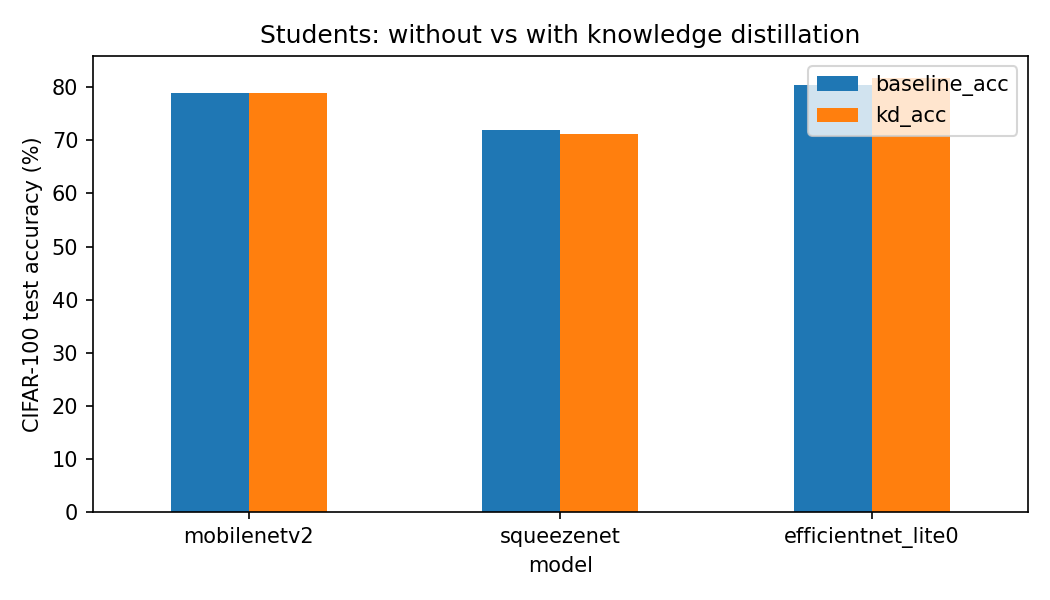

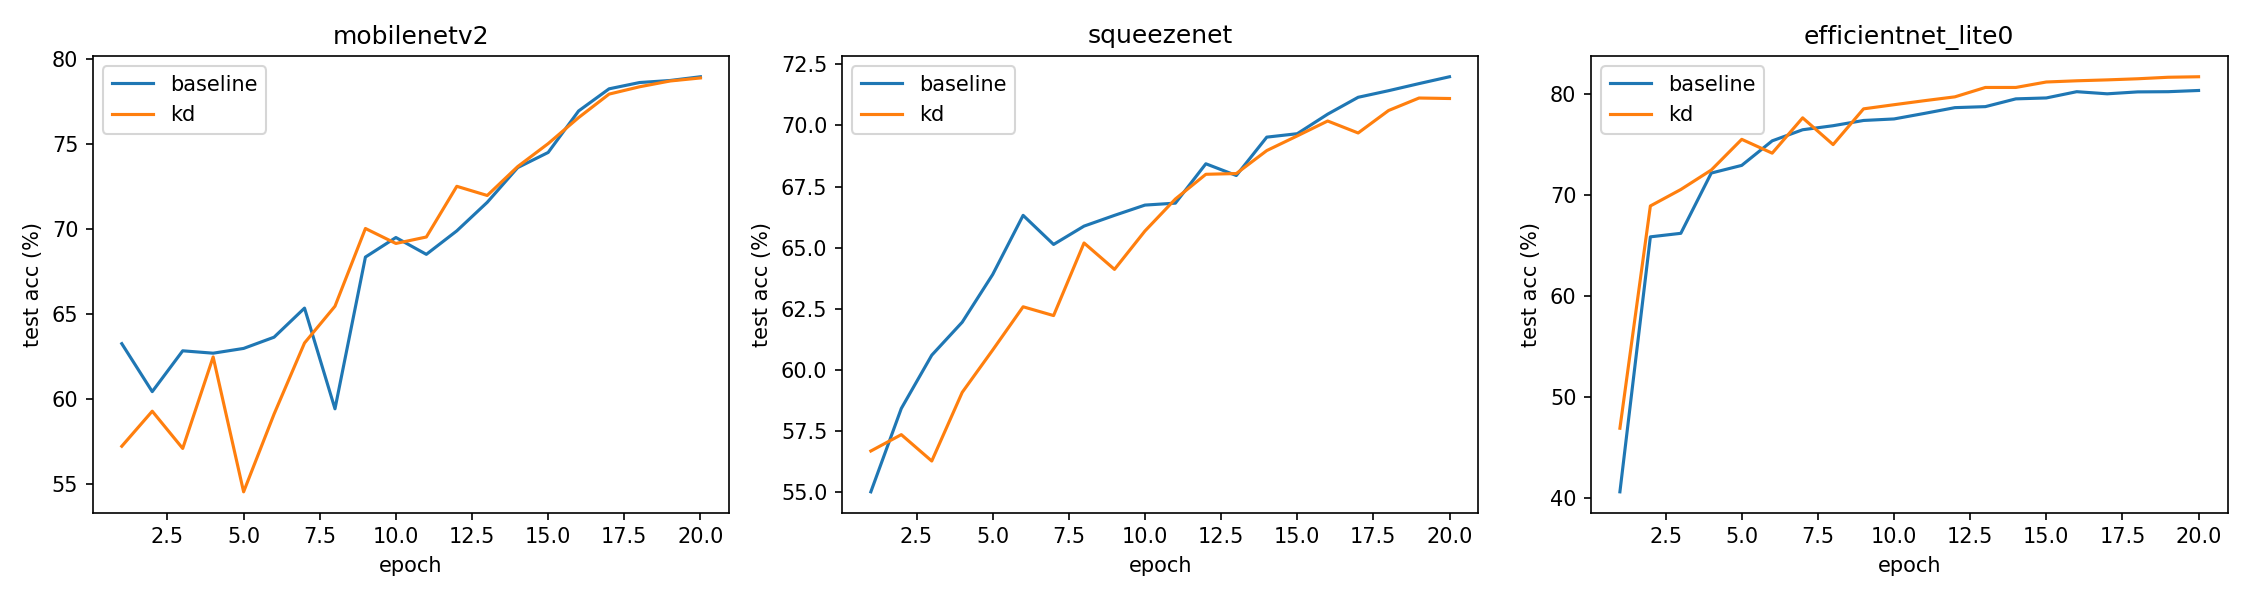

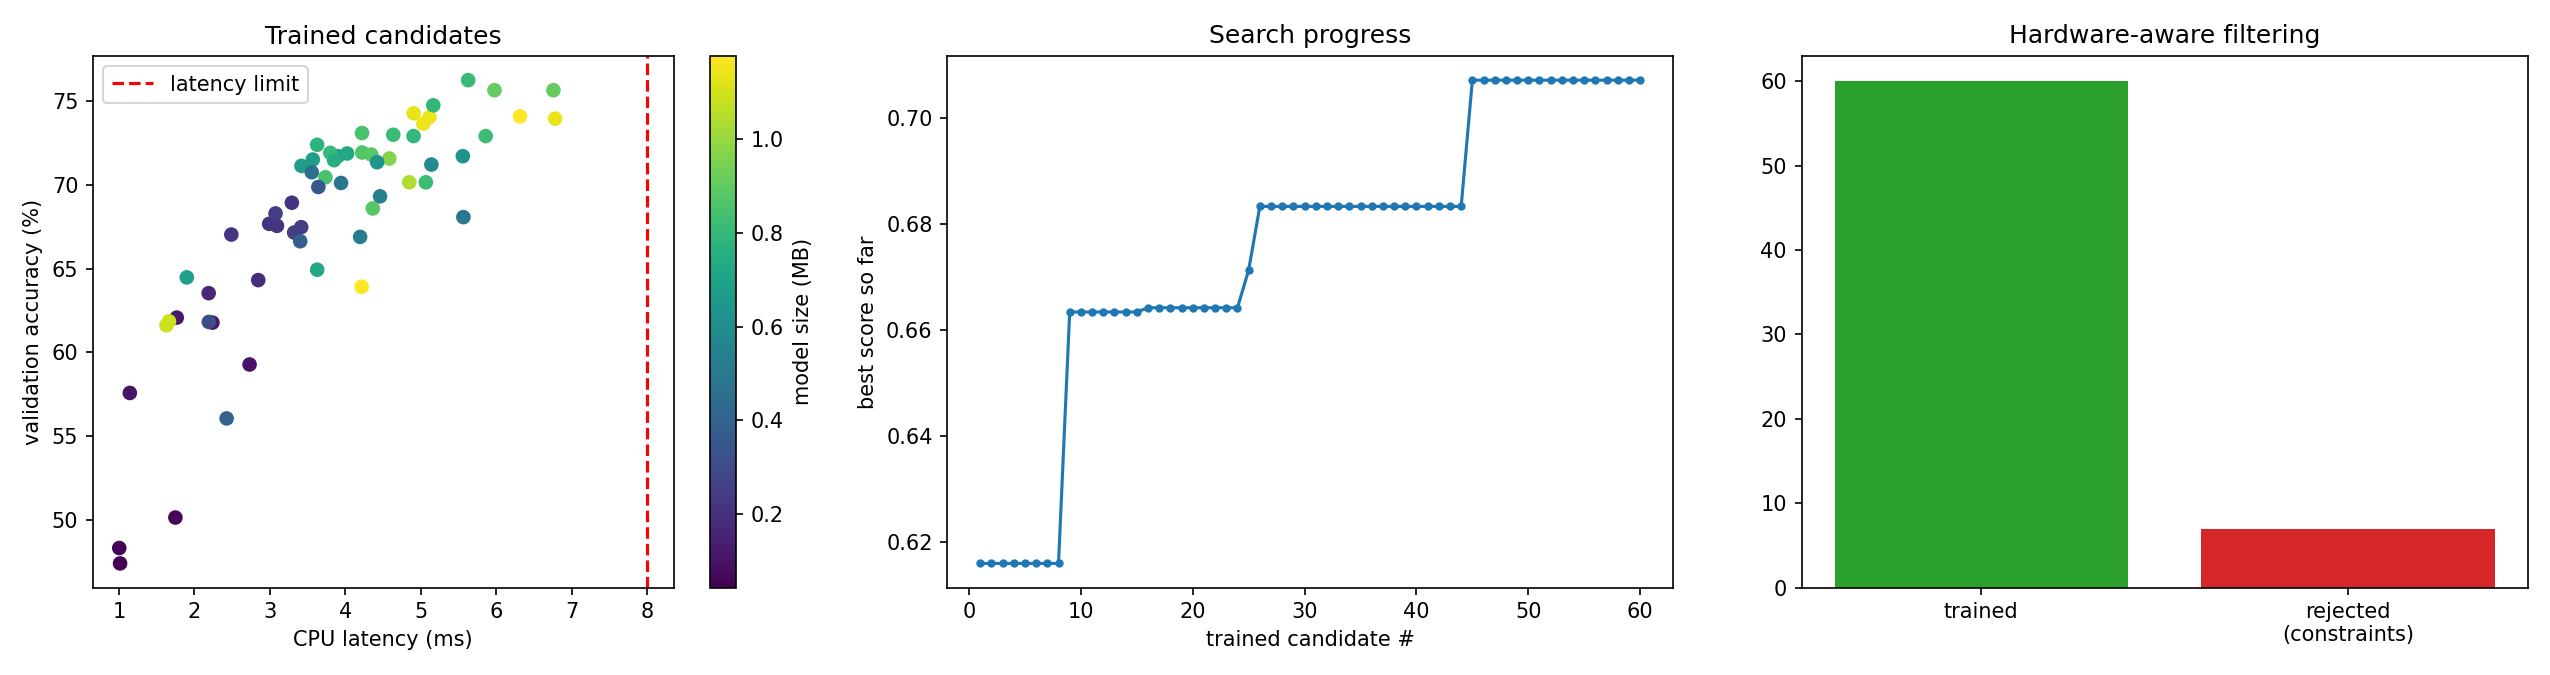

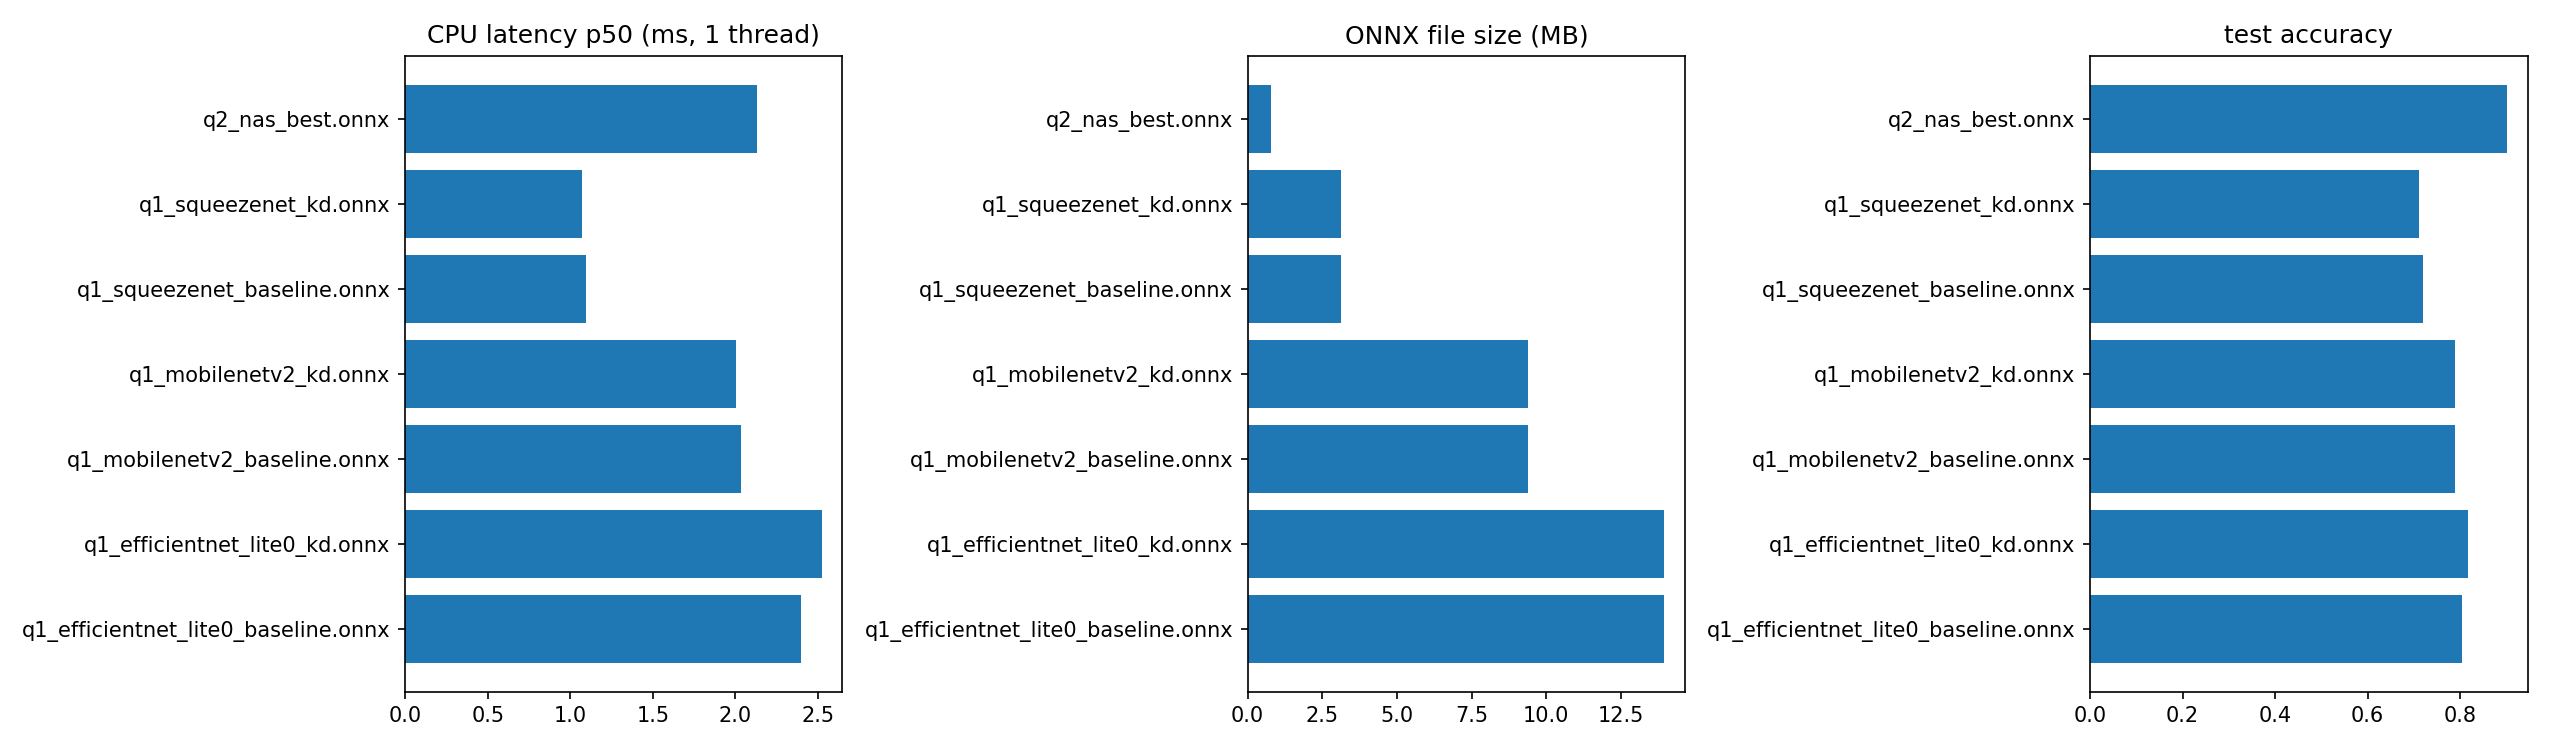

In [43]:
# 13) Make the figures and show them (take screenshots of these for the PDF report)
!python report_figures.py
from IPython.display import Image, display
for f in ["fig_q1_kd_vs_baseline.png", "fig_q1_training_curves.png", "fig_q2_nas_search.png", "fig_benchmark.png"]:
    if os.path.exists(f"{RES}/{f}"):
        display(Image(f"{RES}/{f}"))

In [44]:
%%writefile README.md
# Assignment 4 - Edge Computing & Intelligent Systems

**Q1** Knowledge distillation: ResNet-50 teacher (CIFAR-100) -> MobileNetV2 / SqueezeNet / EfficientNet-Lite0 students, compared with students trained without distillation, then exported to ONNX and run with ONNX Runtime on the CPU.
**Q2** Hardware-aware Neural Architecture Search (evolutionary search, CIFAR-10) that measures real CPU latency and model size, rejects architectures that break the limits, trains the best one from scratch and exports it to ONNX.

Everything was run in a Kaggle notebook (GPU for training, CPU for latency/ONNX measurements). The notebook writes all the `.py` files below.

## Folder structure
```
config.py                 all settings (epochs, KD temperature/alpha/beta, NAS budget, hardware limits)
common.py                 shared code: GPU data pipeline, training loop, ONNX / ONNX-Runtime / timing helpers
q1_distillation/
  teacher.py              ResNet-50 teacher definition
  students.py             MobileNetV2, SqueezeNet, EfficientNet-Lite0
  distillation.py         KD loss: soft targets + temperature + hard labels + feature-based distillation
  train_teacher.py        trains the teacher
  train_baseline.py       trains the 3 students WITHOUT distillation
  train_kd.py             trains the 3 students WITH distillation
  compare_results.py      baseline-vs-KD table
  inference.py            unified inference for all students (PyTorch)
  export_onnx.py          exports students to ONNX and verifies them
q2_nas/
  search_space.py         search space + automatic architecture generator
  hardware.py             measured CPU latency, model size, peak memory + constraints
  nas_search.py           evolutionary hardware-aware search
  train_best.py           trains the best architecture from scratch
  inference.py            inference for the NAS model (PyTorch)
  export_onnx.py          exports the NAS model to ONNX and verifies it
onnx_inference/run_onnx_cpu.py   ONNX Runtime CPU inference for every ONNX model
benchmarking/benchmark.py        automatic benchmark -> results/benchmark_results.csv
report_figures.py         creates the figures used in the report
checkpoints/              trained weights (teacher stored in fp16 to stay under GitHub's 100 MB limit)
onnx_models/              exported ONNX models (input: raw image batch (N,3,32,32) in 0..1, output: class scores)
results/                  training logs, metrics, NAS history/best config, benchmark CSV, figures
```

## Install
```bash
pip install -r requirements.txt
```
A GPU is recommended for training (`train_*.py`, `nas_search.py`). ONNX inference and benchmarking only need the CPU.

## Run (in this order, from the repository root)
```bash
# ---------- Q1
python q1_distillation/train_teacher.py
python q1_distillation/train_baseline.py
python q1_distillation/train_kd.py
python q1_distillation/compare_results.py
python q1_distillation/inference.py --all
python q1_distillation/export_onnx.py
# ---------- Q2
python q2_nas/nas_search.py
python q2_nas/train_best.py
python q2_nas/inference.py
python q2_nas/export_onnx.py
# ---------- ONNX Runtime + benchmark + figures
python onnx_inference/run_onnx_cpu.py
python benchmarking/benchmark.py
python report_figures.py
```
Predict one picture:
```bash
python q1_distillation/inference.py --model mobilenetv2 --variant kd --image my_image.jpg
python onnx_inference/run_onnx_cpu.py --model onnx_models/q2_nas_best.onnx --image my_image.jpg
```
Every training script skips work whose checkpoint already exists (use `--force` to retrain). `FAST_DEV=1 python ...` runs a tiny smoke test and writes to `_dev_outputs/`.

## Design notes
* CIFAR images are enlarged to 96x96 for Q1 (ImageNet-pretrained backbones need bigger pictures). The teacher, the baseline students and the KD students all start from the same ImageNet weights, so the only difference between baseline and KD is the teacher's help.
* KD loss = alpha * T^2 * KL(soft targets) + (1-alpha) * cross-entropy + beta * feature loss (student feature map -> 1x1 conv connector -> normalised MSE against the teacher's last feature map).
* Accuracy is reported from the LAST epoch (no picking the best epoch on the test set). Q2 uses a separate validation split for the search; the test set is only used once at the end.
* Q2 latency = median of repeated CPU runs (batch 1, 1 thread); size = saved float32 weights; peak memory during the search is an estimate (weights + largest layer input/output), the benchmark script measures the real peak process memory per ONNX model.
* Preprocessing (resize + normalisation) is inside the ONNX models, so inference only needs the raw 32x32 image.

Writing README.md


In [45]:
# 14) Package: one ZIP with the whole repository (download it from the Output tab, then unzip and push to GitHub)
import zipfile
if FAST_DEV:
    print("!! FAST_DEV is True - this was only the smoke test. Set FAST_DEV = False and run everything again before submitting.")
SKIP = {"_dev_outputs", "__pycache__", "data", ".ipynb_checkpoints"}
zip_path = "/kaggle/working/edge_assignment4_repo.zip" if os.path.exists("/kaggle/working") else os.path.abspath("edge_assignment4_repo.zip")
big = []
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder, dirs, files in os.walk(ROOT):
        dirs[:] = [d for d in dirs if d not in SKIP]
        for fn in files:
            full = os.path.join(folder, fn)
            z.write(full, os.path.join("edge_assignment4", os.path.relpath(full, ROOT)))
            if os.path.getsize(full) > 95e6:
                big.append(full)
print("ZIP created:", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)")
print("Files bigger than 95 MB (GitHub limit is 100 MB):", big if big else "none - good")
print()
for folder in ["checkpoints", "onnx_models", "results"]:
    print(folder + "/")
    for fn in sorted(os.listdir(os.path.join(ROOT, folder))):
        print(f"   {fn:<45}{os.path.getsize(os.path.join(ROOT, folder, fn))/1e6:8.2f} MB")

ZIP created: /kaggle/working/edge_assignment4_repo.zip (144.9 MB)
Files bigger than 95 MB (GitHub limit is 100 MB): none - good

checkpoints/
   q1_baseline_efficientnet_lite0.pth              14.26 MB
   q1_baseline_mobilenetv2.pth                      9.64 MB
   q1_baseline_squeezenet.pth                       3.11 MB
   q1_kd_efficientnet_lite0.pth                    14.26 MB
   q1_kd_mobilenetv2.pth                            9.64 MB
   q1_kd_squeezenet.pth                             3.11 MB
   q1_teacher_resnet50.pth                         47.63 MB
   q2_nas_best.pth                                  0.81 MB
onnx_models/
   q1_efficientnet_lite0_baseline.onnx             13.95 MB
   q1_efficientnet_lite0_kd.onnx                   13.95 MB
   q1_mobilenetv2_baseline.onnx                     9.38 MB
   q1_mobilenetv2_kd.onnx                           9.38 MB
   q1_squeezenet_baseline.onnx                      3.11 MB
   q1_squeezenet_kd.onnx                            3.11 MB
   q2

## After the run - what to do
1. Open the **Output** tab of the Kaggle notebook and download `edge_assignment4_repo.zip` (or the whole `edge_assignment4` folder).
2. Unzip it, create a GitHub repository, upload the unzipped files (checkpoints, ONNX models and results are already inside).
3. Take screenshots of the important outputs of this notebook (training logs, `baseline_vs_kd` table, NAS results, benchmark table, ONNX export check) and put them in the repo folder `screenshots/` and in the PDF report.
4. Send me the notebook with its outputs and I will help write the technical report.